<a href="https://colab.research.google.com/github/willismax/MediaSystem-Python-Course/blob/main/course-115-v2/colab/W08_LoRA%E5%BE%AE%E8%AA%BF%E8%88%87%E8%A6%96%E8%A6%BA%E4%B8%80%E8%87%B4%E6%80%A7%E8%A8%AD%E8%A8%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W08 LoRA、資料品質與影像一致性｜實作版
> **課程**：多媒體系統（115 學年度日間部）｜ **模組**：模組 B｜生成影像與視覺敘事 ｜ **週次**：W08
> **核心問題**：Prompt 控制不住某個角色時，可以讓模型學新特徵嗎？一組影像要怎麼維持角色、風格、色彩與構圖的一致性？
> **教學設計理念**：本 Notebook 依據「**問題 → 原理 → 實驗 → 驗證 → 反思**」五步學習法設計，落實 **CGRF 提示工程框架** 與 **三道防線驗證法**（閱讀理解、預測執行、邊界測試）。

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)

---
### 📌 本週學習目標
1. 算得出 LoRA 省下多少參數：$\Delta W = BA$，參數量從 $d_{out}d_{in}$ 變成 $r(d_{in}+d_{out})$。
2. 親手訓練一個 LoRA，看懂「凍結 $W$、只學 $A$ 與 $B$」在程式裡長什麼樣子。
3. 說明 Rank 與 LoRA Scale 是**實驗變因**，不是品質等級。
4. 用實驗重現 Concept Entanglement：資料裡剛好一起出現的特徵，會被模型當成 Concept 的一部分。
5. 建立 Dataset Card、Visual Specification 與 Prompt Template，並用 Rubric 評估一致性。

### 這份 Notebook 怎麼用
每個 Lab 都照同一個節奏走：

| 步驟 | 你要做的事 |
| --- | --- |
| 問題 | 讀一段情境，知道這個 Lab 要回答什麼 |
| 預測 | **先**在「✍️ 我的預測」格寫下答案，再執行程式 |
| 實驗 | 執行程式；看到「🔧 動手改」時，一次只改一個變因 |
| 觀察 | 把看到的數字或圖片寫進「👀 觀察」格 |
| 反思 | 回答 1～2 題，對照講義章節 |

預測寫錯沒有關係，評分看的是「預測 → 結果 → 解釋」有沒有接起來。

| Lab | 軌道 | 主題 | 對應講義 | 預估時間 |
| --- | --- | --- | --- | --- |
| 1 | A 必做 | 參數帳：Full vs LoRA | 8.4–8.6 | 5 分鐘 |
| 2 | A 必做 | 「低秩」是什麼：SVD 影像重建 | 8.4 | 10 分鐘 |
| 3 | A 必做 | 親手訓練一個 LoRA＋Scale Sweep | 8.3–8.7、8.19–8.20 | 20 分鐘 |
| 4 | A 必做 | Concept Entanglement 與資料多樣性 | 8.12–8.14 | 15 分鐘 |
| 5 | A 必做 | Dataset Card 與資料偏差檢查 | 8.9–8.11、8.25 | 15 分鐘 |
| 6 | A 必做 | Visual Specification＋Prompt Template | 8.15–8.18 | 10 分鐘 |
| 7 | A 必做 | 一致性評分 Rubric | 8.19、8.22 | 10 分鐘 |
| 8 | B 選做 | Base vs LoRA＋Weight Sweep（SD 1.5） | 8.19–8.21、8.24 | 15 分鐘 |
| 9 | B 選做 | 六張影像故事組＋自動一致性指標 | 8.27 | 15 分鐘 |
| 10 | B 選做 | 自己訓練 DreamBooth-LoRA | 8.8、8.23 Route C | 20–30 分鐘 |

**軌道 A**（Lab 1–7）只用 CPU，Colab 預設的套件就夠，每個 Lab 執行時間都在 1 分鐘內。**軌道 B**（Lab 8–10）需要 Colab T4 GPU，沒有 GPU 時程式格會自動跳過。

執行順序：先執行下方「環境設定」，之後每個 Lab 都可以單獨執行。

## 0. 環境設定（必做，只要執行一次）
下面這格會載入套件、固定亂數種子，並設定 Matplotlib 中文字型。字型下載失敗也不會中斷，只是圖上的中文可能顯示成方框。

In [ ]:
# 修正 torchao 與 diffusers 版本衝突，更新後請重啟執行階段
!pip install -Uq torchao diffusers

In [ ]:
# 環境設定：套件、亂數種子、中文字型
import os, sys, time, math, json, warnings, urllib.request
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
IN_COLAB = "google.colab" in sys.modules
SEED = 42
np.random.seed(SEED)

FONT_PATH = "TaipeiSansTCBeta-Regular.ttf"
FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FALLBACK_FONTS = ["Taipei Sans TC Beta", "Noto Sans CJK TC", "Noto Sans TC", "Noto Sans CJK JP",
                  "Microsoft JhengHei", "PingFang TC", "Heiti TC", "WenQuanYi Zen Hei"]


def setup_chinese_font():
    """依序嘗試：課程字型檔 → 系統已安裝的中文字型。全部失敗時只印提醒，不中斷。"""
    if not (os.path.exists(FONT_PATH) and os.path.getsize(FONT_PATH) > 100_000):
        try:
            urllib.request.urlretrieve(FONT_URL, FONT_PATH)
        except Exception as e:
            print("課程字型下載失敗（", type(e).__name__, "），改找系統字型。")
    # Google Drive 有時回傳 HTML 頁面而不是字型檔，用檔案大小過濾
    if os.path.exists(FONT_PATH) and os.path.getsize(FONT_PATH) < 100_000:
        os.remove(FONT_PATH)
    if os.path.exists(FONT_PATH):
        try:
            font_manager.fontManager.addfont(FONT_PATH)
        except Exception as e:
            print("字型檔無法載入：", e)
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in FALLBACK_FONTS:
        if name in installed:
            plt.rcParams["font.family"] = "sans-serif"
            plt.rcParams["font.sans-serif"] = [name, "DejaVu Sans"]
            plt.rcParams["axes.unicode_minus"] = False
            return name
    print("⚠️ 找不到中文字型，圖表中文可能顯示為方框，但不影響實驗結果。")
    return None


FONT_NAME = setup_chinese_font()
print("中文字型：", FONT_NAME)
print("Python", sys.version.split()[0], "｜NumPy", np.__version__, "｜Matplotlib", matplotlib.__version__)
print("在 Colab 執行：", IN_COLAB)

中文字型： Taipei Sans TC Beta
Python 3.13.16 ｜NumPy 2.1.3 ｜Matplotlib 3.10.0
在 Colab 執行： True


---
# 軌道 A｜CPU 核心實驗（必做）
這一段不用 GPU，也不用下載模型。我們把 LoRA 拆成可以親手驗證的小實驗：先算帳，再看「低秩」長什麼樣子，接著自己訓練一個 LoRA，最後處理資料與一致性的問題。

## Lab 1｜參數帳：Full Fine-tuning vs LoRA（講義 8.4–8.6）

### 問題
講義 8.5 說：一個 $4096 \times 4096$ 的矩陣，用 Rank 16 的 LoRA 只要學大約 0.78% 的參數。這個數字怎麼來的？Rank 加大時，參數量怎麼變？有沒有哪個 Rank 會讓 LoRA 反而不省？

### 原理
Full Fine-tuning 要更新整個 $W \in \mathbb{R}^{d_{out}\times d_{in}}$，參數量是 $d_{out} \cdot d_{in}$。

LoRA 凍結 $W$，只學 $\Delta W = BA$，其中 $B \in \mathbb{R}^{d_{out}\times r}$、$A \in \mathbb{R}^{r\times d_{in}}$，參數量是 $r(d_{in}+d_{out})$。

### ✍️ 我的預測（先寫，再執行）
1. $4096 \times 4096$、$r=16$ 時，LoRA 參數量是多少？占 Full 的百分之幾？
2. Rank 從 16 變成 32，LoRA 參數量會變成幾倍？
3. Rank 要大到多少，LoRA 的參數量才會和 Full Fine-tuning 一樣多？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# Lab 1-1：參數帳函式
def lora_param_count(d_out, d_in, r):
    """回傳 (Full 參數量, LoRA 參數量, LoRA/Full 比例)。"""
    if r <= 0:
        raise ValueError(f"rank 必須是正整數，收到 r={r}")
    if r > min(d_out, d_in):
        print(f"⚠️ r={r} 已超過 min(d_out, d_in)={min(d_out, d_in)}，BA 的秩不會再增加，只是多花參數。")
    full = d_out * d_in
    lora = r * (d_in + d_out)
    return full, lora, lora / full


full, lora, ratio = lora_param_count(4096, 4096, 16)
print(f"Full Fine-tuning：4096 × 4096 = {full:,}")
print(f"LoRA r=16       ：16 × (4096 + 4096) = {lora:,}")
print(f"比例            ：{lora:,} / {full:,} ≈ {ratio:.2%}")
assert lora == 131_072 and abs(ratio - 0.0078125) < 1e-12  # 與講義 8.5 一致

Full Fine-tuning：4096 × 4096 = 16,777,216
LoRA r=16       ：16 × (4096 + 4096) = 131,072
比例            ：131,072 / 16,777,216 ≈ 0.78%


,rank r,LoRA 參數量,Full 參數量,LoRA / Full
0,1,8192,16777216,0.05%
1,2,16384,16777216,0.10%
2,4,32768,16777216,0.20%
3,8,65536,16777216,0.39%
4,16,131072,16777216,0.78%
5,32,262144,16777216,1.56%
6,64,524288,16777216,3.12%
7,128,1048576,16777216,6.25%
8,256,2097152,16777216,12.50%
9,512,4194304,16777216,25.00%


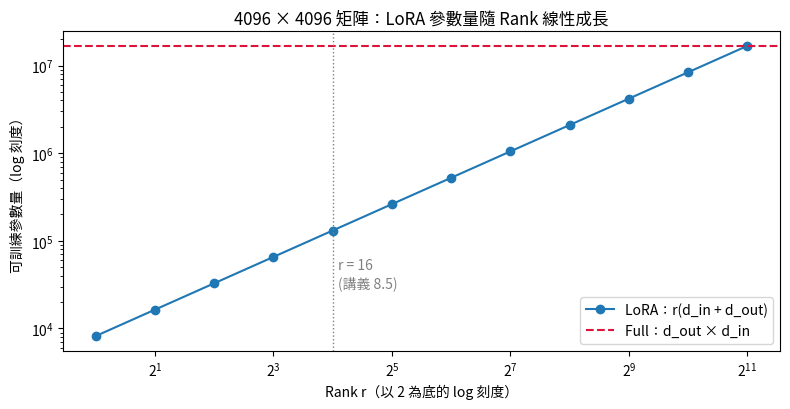

In [ ]:
# Lab 1-2：Rank Sweep 表格與圖
import pandas as pd

D_OUT, D_IN = 4096, 4096
ranks = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]
rows = []
for r in ranks:
    f, l, p = lora_param_count(D_OUT, D_IN, r)
    rows.append({"rank r": r, "LoRA 參數量": l, "Full 參數量": f, "LoRA / Full": f"{p:.2%}"})
df_rank = pd.DataFrame(rows)
display(df_rank)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ranks, [r * (D_IN + D_OUT) for r in ranks], "o-", label="LoRA：r(d_in + d_out)")
ax.axhline(D_OUT * D_IN, color="crimson", ls="--", label="Full：d_out × d_in")
ax.axvline(16, color="gray", ls=":", lw=1)
ax.text(17, 3e4, "r = 16\n(講義 8.5)", color="gray")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("Rank r（以 2 為底的 log 刻度）"); ax.set_ylabel("可訓練參數量（log 刻度）")
ax.set_title("4096 × 4096 矩陣：LoRA 參數量隨 Rank 線性成長")
ax.legend(); plt.tight_layout(); plt.show()

### 🔧 動手改
把下面的維度改成一個**非方陣**，例如 $d_{out}=320,\ d_{in}=768$（形狀類似 SD 1.5 的 Cross-Attention 把 768 維文字特徵投影到 320 維的那一層），再試 `r = 4, 64, 320`。一次只改一個數字。

In [ ]:
# 🔧 動手改：一次只改一個變數
my_d_out, my_d_in, my_r = 320, 768, 4      # TODO: 改成你想測試的值

f, l, p = lora_param_count(my_d_out, my_d_in, my_r)
breakeven = my_d_out * my_d_in / (my_d_in + my_d_out)
print(f"Full = {f:,}，LoRA = {l:,}，比例 = {p:.2%}")
print(f"這個形狀下，r 大約到 {breakeven:.0f} 時 LoRA 就不再省參數。")

Full = 245,760，LoRA = 4,352，比例 = 1.77%
這個形狀下，r 大約到 226 時 LoRA 就不再省參數。


### 👀 觀察
- 4096×4096、r=16 的比例：
- r 加倍時，參數量：
- 損益兩平的 r（方陣時）：

### 反思
1. 講義 8.5 提醒：真正的模型有很多層，LoRA 不一定加在所有層。請說明為什麼「0.78%」只能當作單一矩陣的簡化例子。
2. 參數少代表「效果比較差」嗎？先記下你的想法，Lab 3 會用實驗回答。

## Lab 2｜「低秩」是什麼：用 SVD 重建一張影像（講義 8.4）

### 問題
LoRA 的 L-R 是 Low-Rank。「低秩」到底是什麼意思？為什麼可以只用 $B$ 和 $A$ 兩個瘦長矩陣，就近似一個大矩陣？

### 原理
任何矩陣都可以做奇異值分解（SVD）：$M = U \Sigma V^\top$。只保留前 $k$ 個奇異值，就得到最接近 $M$ 的 rank-$k$ 矩陣：

$$M_k = \underbrace{U_k \Sigma_k}_{B\ (m\times k)}\ \underbrace{V_k^\top}_{A\ (k\times n)}$$

注意它的形狀正好就是 LoRA 的 $BA$，存它需要 $k(m+n)$ 個數字。灰階影像本身就是一個矩陣，我們用 `skimage` 內建的 `camera()`（512×512，不需下載）來看低秩近似的效果。

這裡用影像當類比：有結構的資料，大部分能量集中在前幾個奇異值。LoRA 的假設是**微調所需的 $\Delta W$ 也有類似性質**，所以用低秩的 $BA$ 表示就夠。這是一個假設，Lab 3 的「動手改」會測試它不成立時會發生什麼事。

### ✍️ 我的預測
1. 只保留 $k=1$ 個奇異值時，影像大概會長什麼樣子？
2. 要保留多少個 $k$，你才認得出畫面中的人物和相機？
3. 如果換成一張純雜訊影像，低秩近似的效果會比較好還是比較差？

> 我的預測：
> 1.
> 2.
> 3.

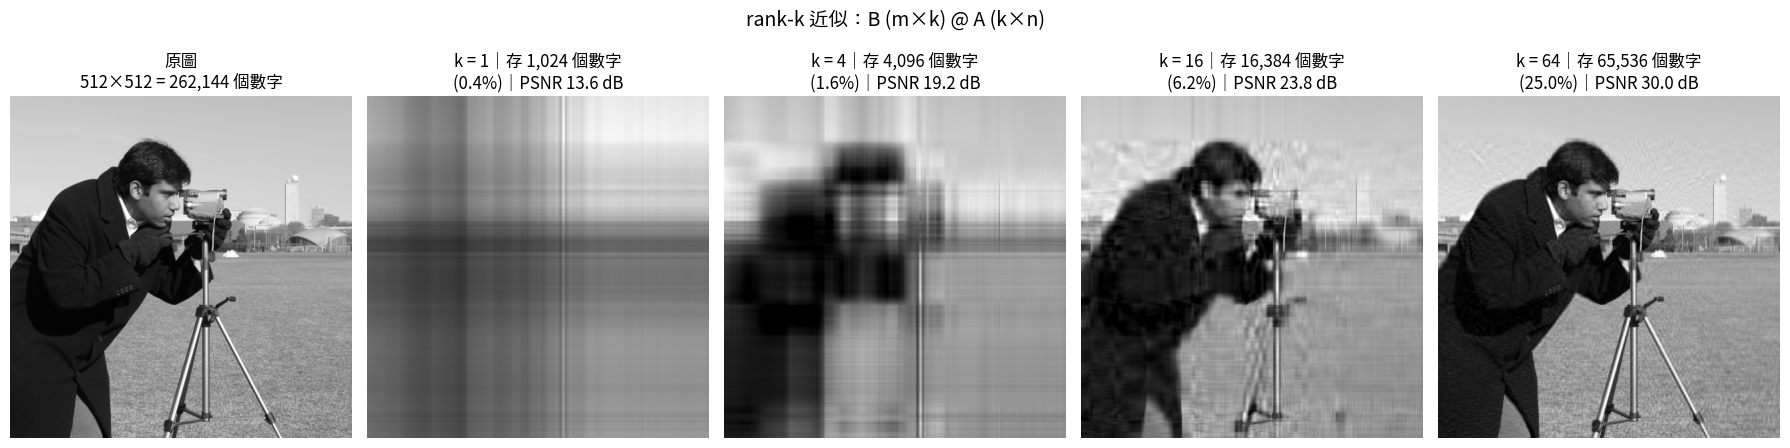

In [ ]:
# Lab 2-1：SVD 與 rank-k 重建
from skimage import data

img = data.camera().astype(np.float64) / 255.0       # 512×512 灰階，skimage 內建
m, n = img.shape
U, S, Vt = np.linalg.svd(img, full_matrices=False)


def rank_k(k):
    B = U[:, :k] * S[:k]          # m × k
    A = Vt[:k, :]                 # k × n
    return np.clip(B @ A, 0, 1)


def psnr(x, y):
    mse = np.mean((x - y) ** 2)
    return 10 * np.log10(1.0 / mse)


ks = [1, 4, 16, 64]
fig, axes = plt.subplots(1, 5, figsize=(18, 4.6))
axes[0].imshow(img, cmap="gray", vmin=0, vmax=1); axes[0].set_title(f"原圖\n{m}×{n} = {m*n:,} 個數字")
for ax, k in zip(axes[1:], ks):
    rec = rank_k(k)
    ax.imshow(rec, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"k = {k}｜存 {k*(m+n):,} 個數字\n({k*(m+n)/(m*n):.1%})｜PSNR {psnr(img, rec):.1f} dB")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.suptitle("rank-k 近似：B (m×k) @ A (k×n)", y=1.06, fontsize=14); plt.show()

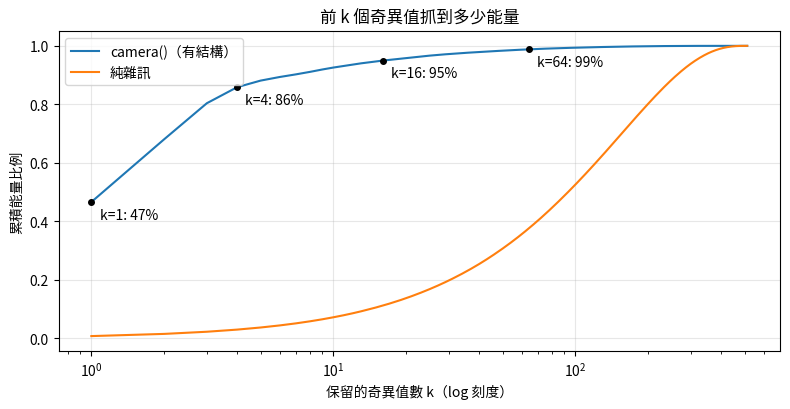

 k camera 能量 雜訊 能量 儲存比例 k(m+n)/(mn)
 1     46.6%  0.8%             0.4%
 4     85.9%  3.0%             1.6%
16     95.0% 11.2%             6.2%
64     98.8% 37.5%            25.0%


In [ ]:
# Lab 2-2：能量曲線，和純雜訊影像比較
rng = np.random.default_rng(SEED)
noise = rng.random((m, n))
S_noise = np.linalg.svd(noise - noise.mean(), compute_uv=False)
S_img_c = np.linalg.svd(img - img.mean(), compute_uv=False)   # 先扣掉平均亮度，兩者比較才公平


def energy(s):
    e = s ** 2
    return np.cumsum(e) / e.sum()


E_img, E_noise = energy(S_img_c), energy(S_noise)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(np.arange(1, len(E_img) + 1), E_img, label="camera()（有結構）")
ax.plot(np.arange(1, len(E_noise) + 1), E_noise, label="純雜訊")
for k in ks:
    ax.plot(k, E_img[k - 1], "ko", ms=4); ax.annotate(f"k={k}: {E_img[k-1]:.0%}", (k, E_img[k - 1]), textcoords="offset points", xytext=(6, -12))
ax.set_xscale("log"); ax.set_xlabel("保留的奇異值數 k（log 刻度）"); ax.set_ylabel("累積能量比例")
ax.set_title("前 k 個奇異值抓到多少能量"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(pd.DataFrame(
    {"k": ks,
      "camera 能量": [f"{E_img[k-1]:.1%}" for k in ks],
      "雜訊 能量": [f"{E_noise[k-1]:.1%}" for k in ks],
      "儲存比例 k(m+n)/(mn)": [f"{k*(m+n)/(m*n):.1%}" for k in ks]}).to_string(index=False))

### 🔧 動手改：拉動滑桿
拉動 `k`，找出「你剛好認得出相機」的最小 k，以及「你看不出和原圖有差別」的最小 k。滑桿無法顯示時（例如沒有安裝 ipywidgets），直接改 `show_k(k=...)` 的數字。

In [ ]:
# 🔧 互動滑桿：rank-k 重建
def show_k(k=16):
    rec = rank_k(k)
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))
    axes[0].imshow(rec, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"k = {k}｜儲存 {k*(m+n)/(m*n):.1%}｜PSNR {psnr(img, rec):.1f} dB")
    axes[1].imshow(np.abs(img - rec), cmap="magma", vmin=0, vmax=0.5); axes[1].set_title("誤差 |原圖 − 重建|")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()


try:
    import ipywidgets as widgets
    widgets.interact(show_k, k=widgets.IntSlider(value=16, min=1, max=128, step=1, continuous_update=False))
except ImportError:
    print("沒有 ipywidgets，改用固定值：")
    show_k(k=16)   # TODO: 改這個數字

interactive(children=(IntSlider(value=16, continuous_update=False, description='k', max=128, min=1), Output())…

### 👀 觀察
- 我認得出相機的最小 k：
- 看不出差別的最小 k：
- camera 與雜訊的能量曲線差在哪裡：

### 反思
1. 用自己的話說明：為什麼 $B$ 是 $m \times k$、$A$ 是 $k \times n$，它們相乘仍然是 $m \times n$？
2. 雜訊影像的低秩近似很差。如果某個微調任務的 $\Delta W$ 像雜訊一樣「沒有結構」，你預期低 Rank 的 LoRA 會怎樣？

## Lab 3｜親手訓練一個 LoRA（講義 8.3–8.7、8.19–8.20）

### 問題
LoRA 說「凍結原本的權重，只學一小組低秩參數」。在程式裡這到底是哪幾行？參數少這麼多，效果會不會差很多？LoRA Scale 調到 1.3 是不是比 1.0「更強更好」？

### 實驗設計
我們用一個 64→64 的線性層當作「預訓練模型」，權重是 $W_0$。新任務的正確答案是 $W_0 + \Delta W_{true}$，其中 $\Delta W_{true}$ 是 **rank 2** 的矩陣，代表「新任務只需要小幅、低秩的調整」。訓練資料只有 128 筆，而且帶有雜訊（雜訊變異數 0.25，這是 test loss 理論上的下限）。

比較五個模型（相同資料、相同 optimizer、相同步數、固定 seed）：

| 模型 | 可訓練的部分 |
| --- | --- |
| Full Fine-tuning | 整個 $W$（64×64） |
| LoRA r = 1, 2, 4, 8 | 只有 $A$ 與 $B$，$W_0$ 凍結 |

LoRA 的初始化照原始論文：$B$ 全為 0，$A$ 是小的隨機值。

### ✍️ 我的預測
1. 訓練開始前（還沒更新任何參數），LoRA 模型的輸出和 Base Model 有沒有差別？為什麼？
2. 五個模型中，**training loss** 最低的是誰？**test loss** 最低的是誰？
3. LoRA r=1 會比 r=2 好還是差？r=8 呢？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# Lab 3-1：資料、Base Model 與 LoRA 層
import torch
import torch.nn as nn

torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))

D, NOISE_STD, STEPS, LR = 64, 0.5, 400, 1e-2


def make_task(true_rank=2, n_train=128, n_test=2000, seed=0):
    """回傳 W0（預訓練權重）、ΔW_true、訓練資料與測試資料。"""
    g = torch.Generator().manual_seed(seed)
    W0 = torch.randn(D, D, generator=g) / math.sqrt(D)
    U_ = torch.randn(D, true_rank, generator=g)
    V_ = torch.randn(true_rank, D, generator=g)
    dW_true = 0.6 * (U_ @ V_) / math.sqrt(D)
    X_tr, X_te = torch.randn(n_train, D, generator=g), torch.randn(n_test, D, generator=g)
    Y_tr = X_tr @ (W0 + dW_true).T + NOISE_STD * torch.randn(n_train, D, generator=g)
    Y_te = X_te @ (W0 + dW_true).T + NOISE_STD * torch.randn(n_test, D, generator=g)
    return W0, dW_true, X_tr, Y_tr, X_te, Y_te


def make_base(W0):
    layer = nn.Linear(D, D, bias=False)
    with torch.no_grad():
        layer.weight.copy_(W0)
    return layer


class LoRALinear(nn.Module):
    """y = W0·x + scale · B·A·x，W0 凍結，只訓練 A、B。"""

    def __init__(self, base: nn.Linear, r: int, seed: int = 0):
        super().__init__()
        self.base = base
        for p in self.base.parameters():
            p.requires_grad_(False)                       # ① 凍結 Pretrained Weight
        g = torch.Generator().manual_seed(seed)
        bound = 1 / math.sqrt(base.in_features)
        self.A = nn.Parameter((torch.rand(r, base.in_features, generator=g) * 2 - 1) * bound)  # ② A：小的隨機值
        self.B = nn.Parameter(torch.zeros(base.out_features, r))                              # ③ B：全 0
        self.scale = 1.0                                  # ④ LoRA Scale（推論時可調）

    def delta_w(self):
        return self.B @ self.A

    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T @ self.B.T)


def n_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


W0, dW_true, X_tr, Y_tr, X_te, Y_te = make_task()
base = make_base(W0)
lora_demo = LoRALinear(make_base(W0), r=2)
with torch.no_grad():
    same = torch.equal(base(X_te), lora_demo(X_te))
print("訓練前，LoRA 輸出 == Base 輸出？", same)
print("Base 的可訓練參數：", n_trainable(base), "｜LoRA r=2 的可訓練參數：", n_trainable(lora_demo))

訓練前，LoRA 輸出 == Base 輸出？ True
Base 的可訓練參數： 4096 ｜LoRA r=2 的可訓練參數： 256


In [ ]:
# Lab 3-2：訓練 Full Fine-tuning 與 LoRA r = 1, 2, 4, 8
def mse(model, X, Y):
    with torch.no_grad():
        return ((model(X) - Y) ** 2).mean().item()


def train(model, X, Y, steps=STEPS, lr=LR):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        loss = ((model(X) - Y) ** 2).mean()
        loss.backward()
        opt.step()
    return model


def learned_delta(model, W0):
    if isinstance(model, LoRALinear):
        return model.delta_w().detach()
    return model.weight.detach() - W0


def run_rank_experiment(true_rank=2, n_train=128, ranks=(1, 2, 4, 8), verbose=True):
    W0, dW_true, X_tr, Y_tr, X_te, Y_te = make_task(true_rank=true_rank, n_train=n_train)
    t0 = time.perf_counter()
    models = {"Base（不訓練）": make_base(W0)}
    full = make_base(W0)                      # Full FT：整個 W 都可訓練
    models["Full Fine-tuning"] = train(full, X_tr, Y_tr)
    for r in ranks:
        lm = LoRALinear(make_base(W0), r=r)
        models[f"LoRA r={r}"] = train(lm, X_tr, Y_tr)
        assert torch.equal(lm.base.weight, W0), "W0 應該保持凍結！"
    rows = []
    for name, mdl in models.items():
        dW = learned_delta(mdl, W0)
        rows.append({"模型": name,
                     "可訓練參數": 0 if name.startswith("Base") else n_trainable(mdl),
                     "train loss": round(mse(mdl, X_tr, Y_tr), 3),
                     "test loss": round(mse(mdl, X_te, Y_te), 3),
                     "ΔW 相對誤差": round((torch.linalg.norm(dW - dW_true) / torch.linalg.norm(dW_true)).item(), 3)})
    table = pd.DataFrame(rows)
    if verbose:
        print(f"TRUE_RANK={true_rank}，N_TRAIN={n_train}，雜訊下限 test loss ≈ {NOISE_STD**2:.2f}（訓練耗時 {time.perf_counter()-t0:.1f} 秒）")
        display(table)
    return models, table, dW_true, W0, (X_te, Y_te)


models, table3, dW_true, W0, (X_te, Y_te) = run_rank_experiment()

TRUE_RANK=2，N_TRAIN=128，雜訊下限 test loss ≈ 0.25（訓練耗時 6.8 秒）


,模型,可訓練參數,train loss,test loss,ΔW 相對誤差
0,Base（不訓練）,0,0.971,0.873,1.000
1,Full Fine-tuning,4096,0.125,0.515,0.644
2,LoRA r=1,128,0.524,0.520,0.653
3,LoRA r=2,256,0.240,0.262,0.135
4,LoRA r=4,512,0.227,0.288,0.243
5,LoRA r=8,1024,0.205,0.343,0.379


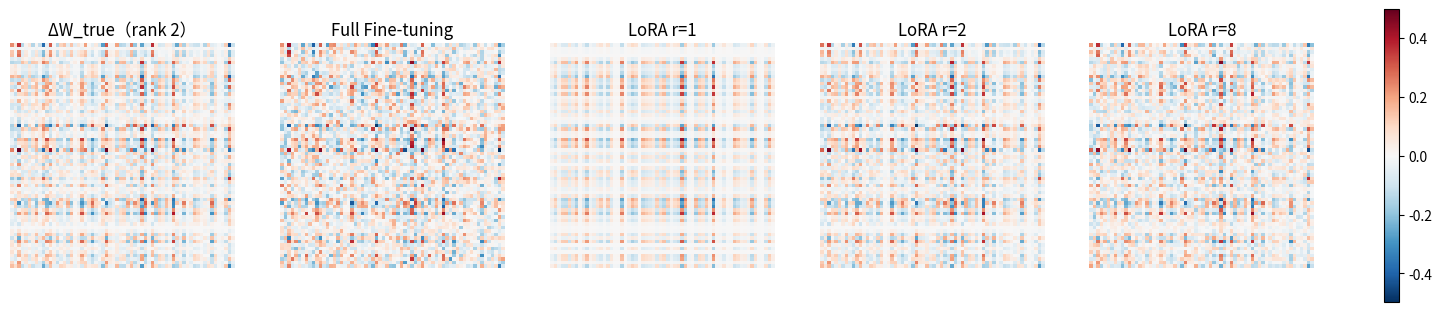

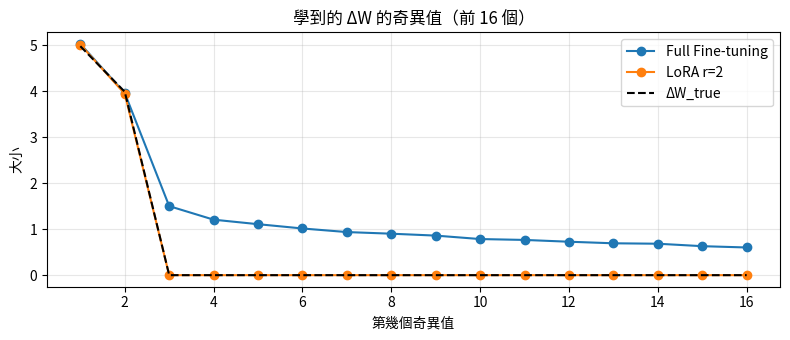

In [ ]:
# Lab 3-3：學到的 ΔW 長什麼樣子？
show = ["Full Fine-tuning", "LoRA r=1", "LoRA r=2", "LoRA r=8"]
mats = [dW_true] + [learned_delta(models[k], W0) for k in show]
titles = ["ΔW_true（rank 2）"] + show
vmax = float(dW_true.abs().max())
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, M, t in zip(axes, mats, titles):
    im = ax.imshow(M.numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(t); ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.015)
plt.show()

# 奇異值：Full FT 學到的 ΔW 有多少個「方向」？
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ["Full Fine-tuning", "LoRA r=2"]:
    s = torch.linalg.svdvals(learned_delta(models[name], W0)).numpy()
    ax.plot(np.arange(1, 17), s[:16], "o-", label=name)
ax.plot(np.arange(1, 17), torch.linalg.svdvals(dW_true).numpy()[:16], "k--", label="ΔW_true")
ax.set_xlabel("第幾個奇異值"); ax.set_ylabel("大小"); ax.set_title("學到的 ΔW 的奇異值（前 16 個）")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

### LoRA Scale Sweep：Scale 是旋鈕，不是品質百分比
訓練好的 LoRA 在推論時可以乘上一個 Scale：$y = W_0 x + s \cdot BAx$。我們用 r=2 的 LoRA，在**沒看過的測試資料**上比較 $s = 0.0, 0.4, 0.7, 1.0, 1.3$，同時看兩件事：

- **新任務誤差**：和新任務正確答案差多少（越低越好）。
- **偏離 Base 的程度**：輸出和原本 Base Model 差多少。這可以想成「原本能力被改掉多少」。

### ✍️ 我的預測
1. $s=0$ 時，模型等於什麼？
2. $s=1.3$ 的新任務誤差會比 $s=1.0$ 低還是高？

> 我的預測：
> 1.
> 2.

,LoRA Scale,新任務誤差 (test MSE),偏離 Base (MSE),輸出與 Base 完全相同？
0,0.0,0.873,0.000,True
1,0.4,0.478,0.100,False
2,0.7,0.314,0.307,False
3,1.0,0.262,0.626,False
4,1.3,0.323,1.058,False


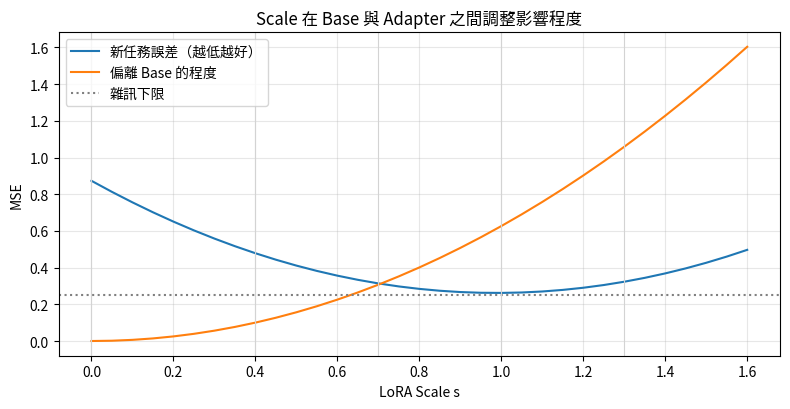

In [ ]:
# Lab 3-4：LoRA Scale Sweep（r=2）
lora2 = models["LoRA r=2"]
base_out = models["Base（不訓練）"](X_te).detach()
SCALES = [0.0, 0.4, 0.7, 1.0, 1.3]

rows = []
for s in SCALES:
    lora2.scale = s
    with torch.no_grad():
        out = lora2(X_te)
    rows.append({"LoRA Scale": s,
                 "新任務誤差 (test MSE)": round(((out - Y_te) ** 2).mean().item(), 3),
                 "偏離 Base (MSE)": round(((out - base_out) ** 2).mean().item(), 3),
                 "輸出與 Base 完全相同？": bool(torch.equal(out, base_out))})
sweep = pd.DataFrame(rows)
display(sweep)

fine = np.linspace(0, 1.6, 33)
task_err, drift = [], []
for s in fine:
    lora2.scale = float(s)
    with torch.no_grad():
        out = lora2(X_te)
    task_err.append(((out - Y_te) ** 2).mean().item()); drift.append(((out - base_out) ** 2).mean().item())
lora2.scale = 1.0   # 復原

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(fine, task_err, label="新任務誤差（越低越好）")
ax.plot(fine, drift, label="偏離 Base 的程度")
ax.axhline(NOISE_STD ** 2, color="gray", ls=":", label="雜訊下限")
for s in SCALES:
    ax.axvline(s, color="lightgray", lw=0.8)
ax.set_xlabel("LoRA Scale s"); ax.set_ylabel("MSE"); ax.set_title("Scale 在 Base 與 Adapter 之間調整影響程度")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

### 🔧 動手改 1：真實的 ΔW 不是低秩時
把 `MY_TRUE_RANK` 改成 6（新任務需要 6 個方向的調整），重跑。先預測：r=2 和 r=8 誰的 test loss 比較低？

In [ ]:
# 🔧 動手改 1
MY_TRUE_RANK = 2      # TODO: 改成 6 再執行
_ = run_rank_experiment(true_rank=MY_TRUE_RANK, n_train=128)

TRUE_RANK=2，N_TRAIN=128，雜訊下限 test loss ≈ 0.25（訓練耗時 7.1 秒）


,模型,可訓練參數,train loss,test loss,ΔW 相對誤差
0,Base（不訓練）,0,0.971,0.873,1.000
1,Full Fine-tuning,4096,0.125,0.515,0.644
2,LoRA r=1,128,0.524,0.520,0.653
3,LoRA r=2,256,0.240,0.262,0.135
4,LoRA r=4,512,0.227,0.288,0.243
5,LoRA r=8,1024,0.205,0.343,0.379


### 🔧 動手改 2：資料變多時
把 `MY_N_TRAIN` 從 128 改成 2000（TRUE_RANK 改回 2）。先預測：Full Fine-tuning 和 LoRA r=2 的差距會變大還是變小？

In [ ]:
# 🔧 動手改 2
MY_N_TRAIN = 128      # TODO: 改成 2000 再執行
_ = run_rank_experiment(true_rank=2, n_train=MY_N_TRAIN)

TRUE_RANK=2，N_TRAIN=128，雜訊下限 test loss ≈ 0.25（訓練耗時 9.2 秒）


,模型,可訓練參數,train loss,test loss,ΔW 相對誤差
0,Base（不訓練）,0,0.971,0.873,1.000
1,Full Fine-tuning,4096,0.125,0.515,0.644
2,LoRA r=1,128,0.524,0.520,0.653
3,LoRA r=2,256,0.240,0.262,0.135
4,LoRA r=4,512,0.227,0.288,0.243
5,LoRA r=8,1024,0.205,0.343,0.379


### 👀 觀察
| 模型 | 可訓練參數 | train loss | test loss |
| --- | --- | --- | --- |
| Full Fine-tuning |  |  |  |
| LoRA r=1 |  |  |  |
| LoRA r=2 |  |  |  |
| LoRA r=8 |  |  |  |

- Scale 0.0 時的輸出：
- Scale 1.3 與 1.0 比較：
- 動手改 1（TRUE_RANK=6）的結果：
- 動手改 2（N_TRAIN=2000）的結果：

### 反思
1. Full Fine-tuning 的 train loss 最低，test loss 卻不是最低。這和講義 8.12「過擬合不只是 Training Loss 很低」有什麼關係？
2. 從動手改 1 和 2 來看，「Rank 越大越好」和「LoRA 一定比 Full Fine-tuning 好」為什麼都不成立？請用講義 8.6 的「Experiment Variable」說明。
3. Scale 0.0 就是 Base Model。為什麼講義 8.20 說 Base Model 一定要留作對照組？

## Lab 4｜Concept Entanglement：模型到底把什麼綁在一起？（講義 8.12–8.14）

### 問題
講義 8.12 的例子：資料中人物永遠站在白牆前，結果 Prompt 寫 in a forest，仍然經常出現白牆。模型為什麼會把背景當成角色的一部分？加多少「不一樣的」資料才夠？

### 實驗設計
我們不用生成模型，而是用一個最簡單的分類器來重現同一個現象。

- 角色 A＝**圓形**，角色 B＝**方形**（形狀才是 Identity）。
- 背景有兩種：**白牆**（淺色）與**森林**（綠色條紋）。
- **訓練集**：角色 A 永遠在白牆前，角色 B 永遠在森林裡（Identity 與背景 100% 相關）。
- **交換測試集**：角色 A 放進森林，角色 B 放到白牆前。

分類器是對 32×32×3 像素做 Logistic Regression。它能用的線索有兩種：形狀（只占畫面中央一小塊）和背景（占大部分像素）。

### ✍️ 我的預測
1. 在「和訓練集同分布」的測試集上，準確率大約多少？
2. 在「交換背景」的測試集上，準確率大約多少？
3. 訓練集裡有多少比例的「去相關樣本」（A 在森林、B 在白牆），交換測試的準確率才會超過 80%？

> 我的預測：
> 1.
> 2.
> 3.

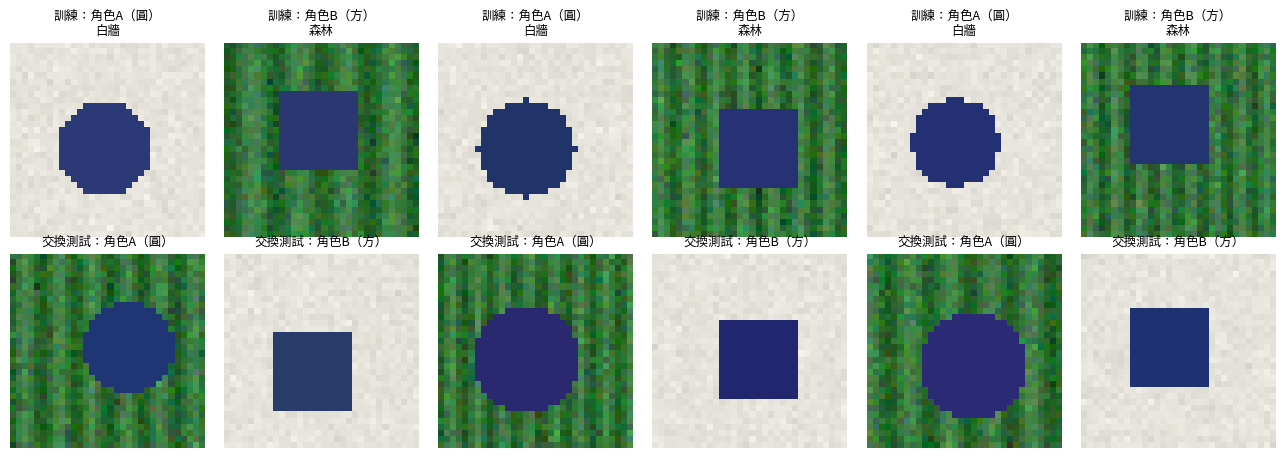

In [ ]:
# Lab 4-1：合成資料
from sklearn.linear_model import LogisticRegression

IMG = 32
yy, xx = np.mgrid[0:IMG, 0:IMG]
WALL, FOREST, FIGURE = np.array([0.90, 0.89, 0.86]), np.array([0.20, 0.45, 0.22]), np.array([0.15, 0.20, 0.45])
NAMES = {0: "角色A（圓）", 1: "角色B（方）"}


def make_image(identity, background, rng):
    img = np.empty((IMG, IMG, 3))
    if background == "白牆":
        img[:] = WALL + rng.normal(0, 0.02, (IMG, IMG, 1))
    else:   # 森林：綠色加上隨機條紋
        stripes = 0.08 * np.sin(xx * rng.uniform(0.8, 1.6) + rng.uniform(0, 2 * np.pi))[..., None]
        img[:] = FOREST + stripes + rng.normal(0, 0.05, (IMG, IMG, 3))
    cx, cy = IMG / 2 + rng.integers(-3, 4), IMG / 2 + rng.integers(-3, 4)
    rad = rng.uniform(7, 9)
    if identity == 0:
        mask = (xx - cx) ** 2 + (yy - cy) ** 2 <= rad ** 2
    else:
        mask = (np.abs(xx - cx) <= rad * 0.89) & (np.abs(yy - cy) <= rad * 0.89)   # 面積和圓形接近
    img[mask] = FIGURE + rng.normal(0, 0.02, 3)
    return np.clip(img, 0, 1)


def make_set(n, p_decor, rng, swapped=False):
    """p_decor：去相關樣本的比例（A 在森林、B 在白牆）。swapped=True 時全部交換。"""
    X, y, bgs = [], [], []
    for i in range(n):
        ident = i % 2
        usual, other = ("白牆", "森林") if ident == 0 else ("森林", "白牆")
        bg = other if (swapped or rng.random() < p_decor) else usual
        X.append(make_image(ident, bg, rng).ravel()); y.append(ident); bgs.append(bg)
    return np.array(X), np.array(y), bgs


rng_test = np.random.default_rng(2026)
X_iid, y_iid, _ = make_set(400, 0.0, rng_test)                 # 同分布測試
X_swap, y_swap, _ = make_set(400, 0.0, rng_test, swapped=True)  # 交換背景測試

X_tr0, y_tr0, bg_tr0 = make_set(400, 0.0, np.random.default_rng(100))
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for j in range(6):
    axes[0, j].imshow(X_tr0[j].reshape(IMG, IMG, 3)); axes[0, j].set_title(f"訓練：{NAMES[y_tr0[j]]}\n{bg_tr0[j]}", fontsize=9)
    axes[1, j].imshow(X_swap[j].reshape(IMG, IMG, 3)); axes[1, j].set_title(f"交換測試：{NAMES[y_swap[j]]}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Lab 4-2：在 100% 相關的資料上訓練
def fit(p_decor, seed=100, n=400):
    X, y, _ = make_set(n, p_decor, np.random.default_rng(seed))
    return LogisticRegression(C=1.0, max_iter=3000).fit(X, y)


def border_share(clf):
    """權重絕對值有多少比例落在外圈背景區（中央 20×20 以外）。"""
    w = np.abs(clf.coef_.reshape(IMG, IMG, 3)).sum(-1)
    center = np.zeros_like(w, dtype=bool); center[6:26, 6:26] = True
    return w[~center].sum() / w.sum()


clf0 = fit(0.0)
print(f"同分布測試準確率：{clf0.score(X_iid, y_iid):.1%}")
print(f"交換背景測試準確率：{clf0.score(X_swap, y_swap):.1%}")
print(f"權重落在外圈背景區的比例：{border_share(clf0):.1%}（外圈占畫面 {1 - 400/1024:.0%}）")

同分布測試準確率：100.0%
交換背景測試準確率：0.0%
權重落在外圈背景區的比例：74.7%（外圈占畫面 61%）


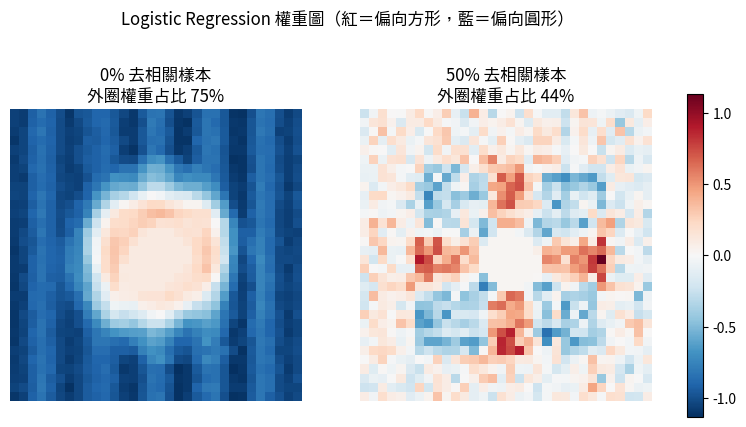

In [ ]:
# Lab 4-3：權重圖：分類器在看哪裡？
clf50 = fit(0.5)


def weight_map(clf):
    return clf.coef_.reshape(IMG, IMG, 3).sum(-1)   # 正值→傾向判成角色B（方），負值→角色A（圓）


fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, clf, t in zip(axes, [clf0, clf50], ["0% 去相關樣本", "50% 去相關樣本"]):
    w = weight_map(clf); v = np.abs(w).max()
    im = ax.imshow(w, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"{t}\n外圈權重占比 {border_share(clf):.0%}"); ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.03)
plt.suptitle("Logistic Regression 權重圖（紅＝偏向方形，藍＝偏向圓形）", y=1.08); plt.show()

### Diversity Sweep：去相關樣本要多少才夠？
固定訓練集大小 400 張，只改變「去相關樣本」的比例：0%、10%、25%、50%。每個比例用 3 個不同 seed 重複，畫平均與標準差。

交換測試         同分布測試       
        mean    std   mean    std
去相關比例                            
0.00   0.000  0.000  1.000  0.000
0.10   0.307  0.096  1.000  0.000
0.25   0.647  0.005  0.996  0.005
0.50   0.919  0.010  0.919  0.001

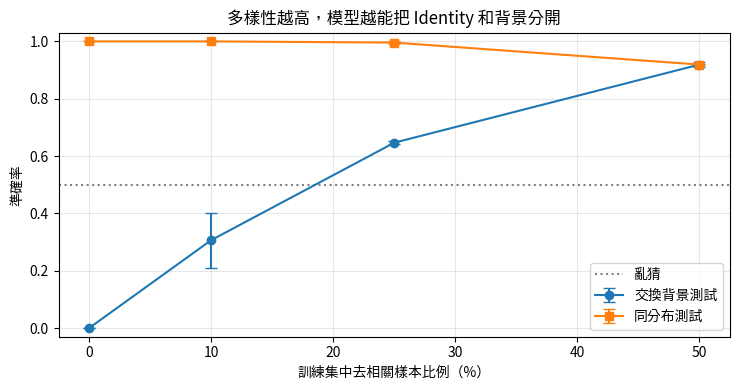

In [ ]:
# Lab 4-4：Diversity Sweep
P_LIST, SEEDS = [0.0, 0.10, 0.25, 0.50], [100, 101, 102]
res = []
for p in P_LIST:
    for sd in SEEDS:
        clf = fit(p, seed=sd)
        res.append({"去相關比例": p, "seed": sd, "交換測試": clf.score(X_swap, y_swap), "同分布測試": clf.score(X_iid, y_iid)})
res = pd.DataFrame(res)
summary = res.groupby("去相關比例")[["交換測試", "同分布測試"]].agg(["mean", "std"]).round(3)
display(summary)

g = res.groupby("去相關比例")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar([p * 100 for p in P_LIST], g["交換測試"].mean(), yerr=g["交換測試"].std(), marker="o", capsize=4, label="交換背景測試")
ax.errorbar([p * 100 for p in P_LIST], g["同分布測試"].mean(), yerr=g["同分布測試"].std(), marker="s", capsize=4, label="同分布測試")
ax.axhline(0.5, color="gray", ls=":", label="亂猜")
ax.set_xlabel("訓練集中去相關樣本比例（%）"); ax.set_ylabel("準確率"); ax.set_ylim(-0.03, 1.03)
ax.set_title("多樣性越高，模型越能把 Identity 和背景分開"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 🔧 動手改：資料變多，但沒有變多樣
講義 8.13 說：Dataset Diversity 不是為了「照片越多越好」。把訓練集從 400 張加到 1600 張，但去相關比例維持 0%。先預測交換測試的準確率，再執行。

In [ ]:
# 🔧 動手改
MY_N, MY_P = 1600, 0.0       # TODO: 試試 (1600, 0.0)、(400, 0.05)、(100, 0.25)
clf_try = fit(MY_P, seed=100, n=MY_N)
print(f"N={MY_N}，去相關比例={MY_P:.0%} → 交換測試 {clf_try.score(X_swap, y_swap):.1%}，同分布測試 {clf_try.score(X_iid, y_iid):.1%}")

N=1600，去相關比例=0% → 交換測試 0.0%，同分布測試 100.0%


### 👀 觀察
| 去相關比例 | 交換測試準確率 | 同分布測試準確率 |
| --- | --- | --- |
| 0% |  |  |
| 10% |  |  |
| 25% |  |  |
| 50% |  |  |

- 0% 時權重圖亮在哪裡：
- 1600 張、0% 的結果：

### 反思
1. 50% 時「同分布測試」的準確率反而比 0% 低一點。為什麼這不代表模型變差？（提示：0% 的模型靠什麼拿到同分布的高分？）
2. 把這個實驗翻譯回生成模型：如果角色 A01 的 20 張訓練圖有 18 張穿紅外套（講義 8.26），你預期 Prompt 寫 wearing a blue shirt 時會發生什麼？要怎麼改資料？
3. 講義 8.14 說「目標 Concept 穩定，非必要因素適度變化」。在這個實驗裡，哪個是目標 Concept？哪個是非必要因素？

## Lab 5｜Dataset Card 與資料偏差檢查（講義 8.9–8.11、8.25）

### 問題
你接手一批要拿來訓練「校園吉祥物 A01」LoRA 的圖片，共 24 張，已經整理成 metadata 表。按下 Train 之前，先回答：這批資料能支持什麼結論？哪裡有偏差？哪幾張不能用？

LoRA 解決的是訓練成本，不會修正資料問題（講義 8.9）。這個 Lab 用程式做第一輪檢查，但最後的判斷要由你寫進 Dataset Card。

### ✍️ 我的預測
先看下面的 metadata 表（執行 Lab 5-1），**在執行檢查程式之前**寫下：
1. 你認為最嚴重的偏差是哪個欄位？
2. 哪兩個欄位彼此高度相關？
3. 有幾張圖的授權或來源有問題？

> 我的預測：
> 1.
> 2.
> 3.

In [ ]:
# Lab 5-1：假想的訓練資料 metadata（24 張）
import pandas as pd
from IPython.display import Markdown, display

# (張數, angle, pose, background, lighting, outfit, caption, source, license)
SPEC = [
    (6, "正面", "站立", "白牆", "室內光", "紅外套", "a photo of A01 mascot standing", "自行繪製", "自有"),
    (3, "45°",  "揮手", "白牆", "室內光", "紅外套", "a photo of A01 mascot waving", "自行繪製", "自有"),
    (3, "側面", "站立", "白牆", "自然光", "紅外套", "A01 mascot standing, side view", "自行繪製", "自有"),
    (2, "正面", "坐姿", "白牆", "室內光", "紅外套", "A01 mascot sitting on a chair", "自行繪製", "自有"),
    (3, "45°",  "站立", "白牆", "室內光", "紅外套", "a photo of A01 mascot standing", "自行繪製", "自有"),
    (2, "正面", "揮手", "白牆", "自然光", "紅外套", "a photo of a mascot waving", "社團活動照片", "已取得社團同意"),
    (1, "側面", "坐姿", "教室", "自然光", "藍襯衫", "A01 mascot sitting in a classroom, wearing a blue shirt", "自行繪製", "自有"),
    (1, "正面", "站立", "教室", "室內光", "白制服", "A01 mascot standing in a classroom, wearing a white uniform", "自行繪製", "自有"),
    (1, "45°",  "揮手", "戶外", "自然光", "藍襯衫", "A01 mascot waving outdoors, wearing a blue shirt", "自行繪製", "自有"),
    (2, "正面", "站立", "白牆", "室內光", "紅外套", "a photo of A01 mascot", "網路搜尋", "不明"),
]
rows = []
for cnt, *fields in SPEC:
    for _ in range(cnt):
        rows.append(dict(zip(["angle", "pose", "background", "lighting", "outfit", "caption", "source", "license"], fields)))
meta = pd.DataFrame(rows)
meta.insert(0, "file", [f"a01_{i:02d}.png" for i in range(1, len(meta) + 1)])
display(meta)

,file,angle,pose,background,lighting,outfit,caption,source,license
0,a01_01.png,正面,站立,白牆,室內光,紅外套,a photo of A01 mascot standing,自行繪製,自有
1,a01_02.png,正面,站立,白牆,室內光,紅外套,a photo of A01 mascot standing,自行繪製,自有
2,a01_03.png,正面,站立,白牆,室內光,紅外套,a photo of A01 mascot standing,自行繪製,自有
3,a01_04.png,正面,站立,白牆,室內光,紅外套,a photo of A01 mascot standing,自行繪製,自有
4,a01_05.png,正面,站立,白牆,室內光,紅外套,a photo of A01 mascot standing,自行繪製,自有
5,a01_06.png,正面,站立,白牆,室內光,紅外套,a photo of A01 mascot standing,自行繪製,自有
6,a01_07.png,45°,揮手,白牆,室內光,紅外套,a photo of A01 mascot waving,自行繪製,自有
7,a01_08.png,45°,揮手,白牆,室內光,紅外套,a photo of A01 mascot waving,自行繪製,自有
8,a01_09.png,45°,揮手,白牆,室內光,紅外套,a photo of A01 mascot waving,自行繪製,自有
9,a01_10.png,側面,站立,白牆,自然光,紅外套,"A01 mascot standing, side view",自行繪製,自有


In [ ]:
# Lab 5-2：自動檢查工具
ATTRS = ["angle", "pose", "background", "lighting", "outfit"]
UNCLEAR_LICENSE = {"不明", "未知", "", "網路搜尋"}
TRIGGER = "A01"


def cramers_v(a, b):
    ct = pd.crosstab(a, b).values.astype(float)
    if min(ct.shape) < 2:
        return 0.0
    n = ct.sum()
    expected = ct.sum(1, keepdims=True) * ct.sum(0, keepdims=True) / n
    chi2 = ((ct - expected) ** 2 / expected).sum()
    return float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))


def audit_dataset(meta, trigger=TRIGGER, dominant=0.75, assoc=0.75):
    issues = []
    for col in ATTRS:
        share = meta[col].value_counts(normalize=True)
        if share.iloc[0] >= dominant:
            issues.append(("多樣性不足", col, f"「{share.index[0]}」占 {share.iloc[0]:.0%}"))
    for i, a in enumerate(ATTRS):
        for b in ATTRS[i + 1:]:
            v = cramers_v(meta[a], meta[b])
            if v >= assoc:
                issues.append(("欄位高度相關", f"{a} × {b}", f"Cramér's V = {v:.2f}"))
    miss = meta[~meta["caption"].str.contains(trigger, regex=False)]
    if len(miss):
        issues.append(("Caption 缺識別詞", "caption", f"{len(miss)} 張沒有「{trigger}」：{', '.join(miss.file)}"))
    eng = {"紅外套": "red jacket", "藍襯衫": "blue shirt", "白制服": "white uniform"}
    undesc = meta[[eng.get(o, o) not in c for o, c in zip(meta.outfit, meta.caption)]]
    if len(undesc):
        issues.append(("Caption 沒描述服裝", "caption", f"{len(undesc)} 張沒寫出服裝，其中 {(undesc.outfit == '紅外套').sum()} 張是紅外套"))
    bad = meta[meta["license"].isin(UNCLEAR_LICENSE) | meta["source"].isin(UNCLEAR_LICENSE)]
    if len(bad):
        issues.append(("授權不清", "license/source", f"{len(bad)} 張：{', '.join(bad.file)}"))
    return pd.DataFrame(issues, columns=["問題類型", "欄位", "說明"])


display(audit_dataset(meta))
print("服裝 × 背景 交叉表：")
display(pd.crosstab(meta["outfit"], meta["background"], margins=True, margins_name="合計"))

,問題類型,欄位,說明
0,多樣性不足,background,「白牆」占 88%
1,多樣性不足,outfit,「紅外套」占 88%
2,欄位高度相關,background × outfit,Cramér's V = 0.79
3,Caption 缺識別詞,caption,"2 張沒有「A01」：a01_18.png, a01_19.png"
4,Caption 沒描述服裝,caption,21 張沒寫出服裝，其中 21 張是紅外套
5,授權不清,license/source,"2 張：a01_23.png, a01_24.png"


服裝 × 背景 交叉表：


background,戶外,教室,白牆,合計
outfit,,,,
白制服,0,1,0,1
紅外套,0,0,21,21
藍襯衫,1,1,0,2
合計,1,2,21,24


### 填寫你的 Dataset Card
把下面字典中寫著 `TODO` 的欄位填完。欄位對應講義 8.10–8.11 的五個面向（Source、Target Concept、Diversity、Caption、Validation），以及 8.25 的資料治理欄位。角度、場景、服裝分布會自動從 metadata 統計，不用手填。

In [ ]:
# Lab 5-3：Dataset Card（TODO 改成你的判斷）
card = {
    "目標": "訓練角色一致性 LoRA：校園吉祥物 A01",
    "Base Model": "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "Concept": "角色：A01",
    "資料來源": "TODO：說明三種來源各有幾張",
    "使用權": "TODO：哪些已確認？哪些要排除？",
    "Resolution": "512 × 512",
    "已知偏差": "TODO：根據自動檢查結果寫",
    "Caption Strategy": "TODO：識別詞怎麼用？服裝、背景、姿勢要不要描述？",
    "Validation Prompts": [
        "a photo of A01 mascot standing",          # TODO：這一條有問題，請替換
        "TODO",
        "TODO",
        "TODO",
    ],
    "Privacy": "TODO：社團活動照片裡有沒有其他人？",
    "Intended Use": "TODO",
    "禁止用途／限制": "TODO",
}


def check_card(card, meta):
    problems = []
    for k, v in card.items():
        vals = v if isinstance(v, list) else [v]
        if any((not str(x).strip()) or "TODO" in str(x) for x in vals):
            problems.append(f"「{k}」尚未完成")
    vps = [p for p in card.get("Validation Prompts", []) if "TODO" not in p]
    if len(card.get("Validation Prompts", [])) < 4:
        problems.append("Validation Prompts 少於 4 條")
    dup = [p for p in vps if p.strip().lower() in set(meta.caption.str.lower())]
    if dup:
        problems.append(f"Validation Prompt 和訓練 Caption 完全相同（講義 8.21）：{dup}")
    return problems


def render_card(card, meta):
    dist = lambda col: "\n".join(f"- {k}：{v}" for k, v in meta[col].value_counts().items())
    lines = ["## Dataset Card"]
    for k, v in card.items():
        lines.append(f"\n### {k}")
        lines.append("\n".join(f"{i}. {x}" for i, x in enumerate(v, 1)) if isinstance(v, list) else str(v))
        if k == "Resolution":
            lines += [f"\n### 圖片數\n{len(meta)}", f"\n### 角度分布\n{dist('angle')}",
                      f"\n### 場景\n{dist('background')}", f"\n### 服裝\n{dist('outfit')}"]
    return "\n".join(lines)


display(Markdown(render_card(card, meta)))
problems = check_card(card, meta)
print(f"尚待處理 {len(problems)} 項：" if problems else "✅ Dataset Card 檢查通過")
for p in problems:
    print(" -", p)

## Dataset Card

### 目標
訓練角色一致性 LoRA：校園吉祥物 A01

### Base Model
stable-diffusion-v1-5/stable-diffusion-v1-5

### Concept
角色：A01

### 資料來源
TODO：說明三種來源各有幾張

### 使用權
TODO：哪些已確認？哪些要排除？

### Resolution
512 × 512

### 圖片數
24

### 角度分布
- 正面：13
- 45°：7
- 側面：4

### 場景
- 白牆：21
- 教室：2
- 戶外：1

### 服裝
- 紅外套：21
- 藍襯衫：2
- 白制服：1

### 已知偏差
TODO：根據自動檢查結果寫

### Caption Strategy
TODO：識別詞怎麼用？服裝、背景、姿勢要不要描述？

### Validation Prompts
1. a photo of A01 mascot standing
2. TODO
3. TODO
4. TODO

### Privacy
TODO：社團活動照片裡有沒有其他人？

### Intended Use
TODO

### 禁止用途／限制
TODO

尚待處理 9 項：
 - 「資料來源」尚未完成
 - 「使用權」尚未完成
 - 「已知偏差」尚未完成
 - 「Caption Strategy」尚未完成
 - 「Validation Prompts」尚未完成
 - 「Privacy」尚未完成
 - 「Intended Use」尚未完成
 - 「禁止用途／限制」尚未完成
 - Validation Prompt 和訓練 Caption 完全相同（講義 8.21）：['a photo of A01 mascot standing']


### 🔧 動手改
1. 把 Dataset Card 填到檢查通過為止。
2. 在 metadata 裡把兩張「網路搜尋／不明」的列刪掉（`meta = meta[meta.license != "不明"]`），再跑一次 `audit_dataset(meta)`。偏差有沒有變好？
3. 邊界測試：把某一列的 license 改成英文 `"unknown"`，檢查程式抓得到嗎？要怎麼改 `UNCLEAR_LICENSE`？

### 👀 觀察
- 自動檢查找到的問題：
- 刪掉授權不清的圖之後，紅外套比例：

### 反思
1. 自動檢查說「outfit × background 高度相關」。對照 Lab 4，這組資料訓練出來的 LoRA 可能出現什麼行為？
2. 程式能抓「授權欄位寫不明」，但抓不到哪些資料治理問題？（講義 8.25：Consent、Privacy、Identity Misuse）

## Lab 6｜Visual Specification＋Prompt Template（講義 8.15–8.18）

### 問題
六張故事圖如果每張都重新寫 Prompt，很容易這張短髮、那張長髮，這張水彩、那張 3D。講義 8.17 的做法是 **Fixed Specification＋Variable Scene**。這個 Lab 把它寫成程式，再加上自動檢查，讓「只有 Scene 會變」這件事可以被驗證。

### ✍️ 我的預測
1. 六個 Prompt 裡，哪些文字應該完全相同？
2. 如果有人在 scene 裡寫了 `long blonde hair`，會造成什麼一致性問題？

> 我的預測：
> 1.
> 2.

In [ ]:
# Lab 6-1：Visual Specification 與 Prompt Template
VISUAL_SPEC = {
    "Character": ["young male student", "short black hair", "round glasses", "navy hoodie", "white sneakers"],
    "Style": ["flat editorial illustration", "clean geometric shapes"],
    "Palette": ["navy and coral color palette"],
    "Lighting": ["soft daylight"],
    "Background": ["minimal university environment"],
    "Composition": ["16:9 composition"],
    "Text": ["no text"],
}
CHARACTER = ", ".join(VISUAL_SPEC["Character"])
STYLE = ", ".join(sum((VISUAL_SPEC[k] for k in ["Style", "Palette", "Lighting", "Background", "Composition", "Text"]), []))

# 只有 action / background / camera 會依 Scene 改變（講義 8.27 Step 3）
SCENES = [
    {"id": "01", "title": "走進校園",   "action": "walking through the campus gate", "background": "tree-lined campus path",        "camera": "medium shot"},
    {"id": "02", "title": "坐在教室",   "action": "sitting at a desk, listening",     "background": "lecture classroom",             "camera": "medium shot"},
    {"id": "03", "title": "操作電腦",   "action": "typing on a laptop",               "background": "computer classroom",            "camera": "medium close-up"},
    {"id": "04", "title": "進入實驗室", "action": "opening the lab door",             "background": "multimedia lab with monitors",  "camera": "medium shot"},
    {"id": "05", "title": "與同學討論", "action": "discussing ideas with a classmate","background": "study corner with whiteboard",  "camera": "medium shot"},
    {"id": "06", "title": "站上舞台",   "action": "presenting a project on stage",    "background": "small auditorium stage",        "camera": "wide shot"},
]


def scene_text(s):
    return f"{s['action']}, {s['background']}, {s['camera']}"


def build_prompt(scene):
    return f"{CHARACTER}, {scene_text(scene)}, {STYLE}"


PROMPTS = [build_prompt(s) for s in SCENES]
for s, p in zip(SCENES, PROMPTS):
    print(f"[{s['id']} {s['title']}]\n{p}\n")

[01 走進校園]
young male student, short black hair, round glasses, navy hoodie, white sneakers, walking through the campus gate, tree-lined campus path, medium shot, flat editorial illustration, clean geometric shapes, navy and coral color palette, soft daylight, minimal university environment, 16:9 composition, no text

[02 坐在教室]
young male student, short black hair, round glasses, navy hoodie, white sneakers, sitting at a desk, listening, lecture classroom, medium shot, flat editorial illustration, clean geometric shapes, navy and coral color palette, soft daylight, minimal university environment, 16:9 composition, no text

[03 操作電腦]
young male student, short black hair, round glasses, navy hoodie, white sneakers, typing on a laptop, computer classroom, medium close-up, flat editorial illustration, clean geometric shapes, navy and coral color palette, soft daylight, minimal university environment, 16:9 composition, no text

[04 進入實驗室]
young male student, short black hair, round glasses, 

In [ ]:
# Lab 6-2：自動檢查：錨點都在、只有 Scene 在變、Scene 不可偷改規格
ANCHORS = [a for k in VISUAL_SPEC for a in VISUAL_SPEC[k]]
# Scene 裡不應出現的詞：會改到角色外觀或畫風的描述
FORBIDDEN_IN_SCENE = ["hair", "glasses", "hoodie", "sneakers", "jacket", "shirt",
                      "watercolor", "3d", "anime", "photo", "realistic", "oil painting", "comic"]


def check_prompts(scenes, build=build_prompt):
    prompts = [build(s) for s in scenes]
    for s, p in zip(scenes, prompts):
        missing = [a for a in ANCHORS if a not in p]
        assert not missing, f"Scene {s['id']} 缺少規格錨點：{missing}"
        assert p.startswith(CHARACTER) and p.endswith(STYLE), f"Scene {s['id']} 的固定部分被改動"
        assert p[len(CHARACTER) + 2: len(p) - len(STYLE) - 2] == scene_text(s), f"Scene {s['id']} 的可變部分不只 Scene"
        hit = [w for w in FORBIDDEN_IN_SCENE if w in scene_text(s).lower()]
        assert not hit, f"Scene {s['id']} 偷改了角色或風格：{hit}"
    words = [len(p.replace(",", " ").split()) for p in prompts]
    print(f"✅ {len(prompts)} 個 Prompt 通過檢查。字數 {min(words)}～{max(words)} 字。")
    if max(words) > 60:
        print("⚠️ SD 1.5 的 CLIP 文字編碼器最多讀 77 個 token，太長的 Prompt 尾端（通常是 STYLE）會被截掉。")
    return prompts


_ = check_prompts(SCENES)

# 邊界測試：故意放一個會破壞一致性的 Scene
bad = dict(SCENES[0], id="99", action="walking with long blonde hair flowing")
try:
    check_prompts(SCENES + [bad])
except AssertionError as e:
    print("❌ 抓到問題：", e)

✅ 6 個 Prompt 通過檢查。字數 40～43 字。
❌ 抓到問題： Scene 99 偷改了角色或風格：['hair']


In [ ]:
# Lab 6-3：Generation Manifest（講義 8.27 Step 4），Lab 9 會讀這個檔
GEN_SETTINGS = {"model": "stable-diffusion-v1-5/stable-diffusion-v1-5", "scheduler": "DPMSolverMultistepScheduler",
                "steps": 25, "guidance_scale": 7.0, "width": 768, "height": 432, "seed": 1234,
                "negative_prompt": "text, watermark, extra fingers, deformed, blurry"}
manifest = [{"scene_id": s["id"], "title": s["title"], "prompt": p, **GEN_SETTINGS} for s, p in zip(SCENES, PROMPTS)]
with open("w08_story_manifest.json", "w", encoding="utf-8") as f:
    json.dump({"visual_spec": VISUAL_SPEC, "frames": manifest}, f, ensure_ascii=False, indent=2)
print("已寫出 w08_story_manifest.json，共", len(manifest), "格")
display(pd.DataFrame(manifest)[["scene_id", "title", "seed", "steps", "guidance_scale"]])

已寫出 w08_story_manifest.json，共 6 格


,scene_id,title,seed,steps,guidance_scale
0,01,走進校園,1234,25,7.0
1,02,坐在教室,1234,25,7.0
2,03,操作電腦,1234,25,7.0
3,04,進入實驗室,1234,25,7.0
4,05,與同學討論,1234,25,7.0
5,06,站上舞台,1234,25,7.0


### 🔧 動手改
1. 把 `VISUAL_SPEC` 換成你自己的角色（例如校園吉祥物），重新產生六個 Prompt。
2. 邊界測試：把 bad scene 的 `long blonde hair` 改成 `blond ponytail`，檢查器還抓得到嗎？`FORBIDDEN_IN_SCENE` 這種關鍵字清單有什麼極限？

### 👀 觀察
- 我的角色規格：
- 檢查器抓不到的寫法：

### 反思
1. 講義 8.18：Prompt Template 已經固定，人物仍然變化很大時，代表什麼？下一步該考慮 Reference／IP-Adapter、ControlNet 還是 LoRA？依據是什麼？
2. 固定 seed 對六張圖的一致性有幫助嗎？會不會也帶來副作用？（Lab 9 會實測）

## Lab 7｜一致性評分 Rubric（講義 8.19、8.22）

### 問題
「感覺比較一致」不能當實驗結論。講義 8.22 建議用 Rubric 給每張圖評分，最後寫得出「使用 LoRA 後，平均 Character Identity 從 2.4 提升到 4.1，但 Prompt Flexibility 從 4.3 降至 3.5」這種句子。

Rubric 維度（1～5 分）：Character Identity、Clothing、Style、Palette、Composition、Scene Compliance。另外加上講義 8.19 Weight Sweep 表格中的 **Prompt Flexibility**，用來觀察「更像」和「更聽 Prompt」之間的取捨。

> ⚠️ 下面的分數是**虛構的示範資料**，只用來示範計算與寫結論的格式。請換成你自己對 Lab 8／Lab 9（或其他工具產生的）圖片的評分。

### ✍️ 我的預測
看示範資料之前先想：加上 LoRA 之後，哪些維度最可能提高？哪個維度最可能下降？

> 我的預測：

In [ ]:
# Lab 7-1：評分工具
DIMS = ["Character Identity", "Clothing", "Style", "Palette", "Composition", "Scene Compliance", "Prompt Flexibility"]


def empty_sheet(conditions=("Base", "LoRA"), images=("v1", "v2", "v3", "v4", "v5")):
    """產生空白評分表，每一列是一張圖。"""
    rows = [{"condition": c, "image": i, **{d: None for d in DIMS}, "note": ""} for c in conditions for i in images]
    return pd.DataFrame(rows)


def validate(sheet):
    vals = sheet[DIMS]
    assert vals.notna().all().all(), "還有空白分數"
    assert vals.isin([1, 2, 3, 4, 5]).all().all(), "分數只能是 1～5 的整數"


def summarize(sheet):
    validate(sheet)
    return sheet.groupby("condition")[DIMS].mean().round(2)


def conclusion(summary, a="Base", b="LoRA", dims=("Character Identity", "Prompt Flexibility")):
    parts = []
    for d in dims:
        x, y = summary.loc[a, d], summary.loc[b, d]
        verb = "提升到" if y > x else ("降至" if y < x else "維持在")
        parts.append(f"{d} 從 {x:.1f} {verb} {y:.1f}")
    return f"使用 {b} 後，平均 " + "，但 ".join(parts) + "。"


# 示範資料（虛構）：5 個 Validation Prompts × 2 個 seed = 每個條件 10 張圖
demo = pd.DataFrame({
    "condition": ["Base"] * 10 + ["LoRA"] * 10,
    "image": [f"vp{i//2+1}_s{i%2}" for i in range(10)] * 2,
    "Character Identity": [2, 3, 2, 3, 2, 2, 3, 2, 3, 2,   4, 4, 5, 4, 4, 4, 4, 4, 4, 4],
    "Clothing":           [3, 3, 2, 3, 2, 3, 3, 2, 3, 3,   4, 5, 4, 4, 4, 5, 4, 4, 4, 4],
    "Style":              [3, 3, 3, 4, 3, 3, 3, 3, 4, 3,   4, 4, 4, 4, 4, 4, 4, 5, 4, 4],
    "Palette":            [3, 3, 3, 3, 3, 3, 4, 3, 3, 3,   4, 4, 4, 4, 3, 4, 4, 4, 4, 4],
    "Composition":        [4, 3, 4, 4, 3, 4, 4, 3, 4, 4,   4, 4, 3, 4, 4, 4, 3, 4, 4, 4],
    "Scene Compliance":   [5, 4, 4, 5, 4, 4, 5, 4, 4, 5,   4, 3, 4, 4, 3, 4, 4, 3, 4, 4],
    "Prompt Flexibility": [5, 4, 4, 5, 4, 4, 5, 4, 4, 4,   4, 3, 4, 3, 3, 4, 3, 4, 3, 4],
})
summary7 = summarize(demo)
display(summary7)
print(conclusion(summary7))

,Character Identity,Clothing,Style,Palette,Composition,Scene Compliance,Prompt Flexibility
condition,,,,,,,
Base,2.4,2.7,3.2,3.1,3.7,4.4,4.3
LoRA,4.1,4.2,4.1,3.9,3.8,3.7,3.5


使用 LoRA 後，平均 Character Identity 從 2.4 提升到 4.1，但 Prompt Flexibility 從 4.3 降至 3.5。


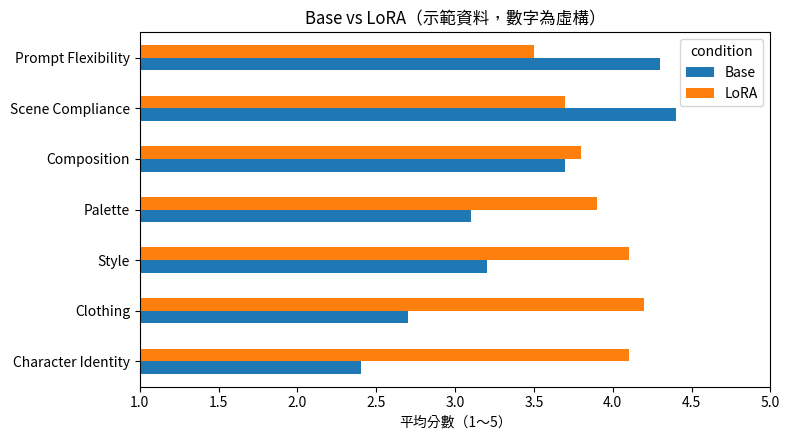

各條件最低分的兩張（下一輪要重新生成，並記錄改了哪個 Condition）：


,condition,image,total,Character Identity,Clothing,Style,Palette,Composition,Scene Compliance,Prompt Flexibility
7,Base,vp4_s1,3.000000,2,2,3,3,3,4,4
4,Base,vp3_s0,3.000000,2,2,3,3,3,4,4
14,LoRA,vp3_s0,3.571429,4,4,4,3,4,3,3
16,LoRA,vp4_s0,3.714286,4,4,4,4,3,4,3


In [ ]:
# Lab 7-2：視覺化與找出最低分的圖（講義 8.27 Step 6：挑最低分的兩張重做）
ax = summary7.T.plot(kind="barh", figsize=(8, 4.5), xlim=(1, 5))
ax.set_xlabel("平均分數（1～5）"); ax.set_title("Base vs LoRA（示範資料，數字為虛構）")
plt.tight_layout(); plt.show()

scored = demo.assign(total=demo[DIMS].mean(axis=1))
worst = scored.sort_values("total").groupby("condition").head(2)
print("各條件最低分的兩張（下一輪要重新生成，並記錄改了哪個 Condition）：")
display(worst[["condition", "image", "total"] + DIMS])

### 🔧 動手改
1. 用 `my_sheet = empty_sheet()` 產生空白表，填入你自己的評分（可以 `my_sheet.to_csv("w08_rubric.csv")` 匯出後用試算表填，再 `pd.read_csv` 讀回來），跑 `summarize` 與 `conclusion`。
2. 邊界測試：在表中故意填一個 `6` 或留空，`validate` 會怎麼反應？

In [ ]:
# 🔧 動手改：你的評分表
my_sheet = empty_sheet()
my_sheet.head()

,condition,image,Character Identity,Clothing,Style,Palette,Composition,Scene Compliance,Prompt Flexibility,note
0,Base,v1,None,None,None,None,None,None,None,
1,Base,v2,None,None,None,None,None,None,None,
2,Base,v3,None,None,None,None,None,None,None,
3,Base,v4,None,None,None,None,None,None,None,
4,Base,v5,None,None,None,None,None,None,None,


### 反思
1. 示範資料中 Character Identity 上升、Prompt Flexibility 下降。如果你的專題是「同一角色出現在六個不同場景」，你會怎麼取捨？
2. 一個人打分數有什麼風險？如果兩位同學的評分差很多，你會怎麼處理？

---
# 軌道 B｜GPU 進階實驗（選做，Colab T4）
這一段需要 GPU。Colab 選單：**執行階段 → 變更執行階段類型 → T4 GPU**，然後重新執行「環境設定」與下面的 Track B 設定格。

軌道 B 對應講義 8.23 的 Route B（使用既有 Adapter）與 Route C（實際 Training）。沒有 GPU 也沒關係，本週必做部分只有軌道 A。

| Lab | 第一次執行約需 | 下載量 |
| --- | --- | --- |
| Track B 設定 | 1～2 分鐘 | 套件 |
| Lab 8 | 3～5 分鐘 | SD 1.5（約 2.5 GB fp16）＋ LoRA 27 MB |
| Lab 9 | 2～3 分鐘 | CLIP（約 600 MB） |
| Lab 10 | 15～25 分鐘 | 訓練腳本、5 張狗狗照片 |

In [ ]:
# Track B 設定：GPU 檢查、安裝套件、共用函式
import subprocess, gc

GPU_OK = False
try:
    import torch
    GPU_OK = torch.cuda.is_available()
except ImportError:
    pass

if GPU_OK:
    print("✅ GPU：", torch.cuda.get_device_name(0))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "diffusers==0.41.0", "transformers", "accelerate", "peft", "ftfy"], check=True)
    import diffusers
    print("diffusers", diffusers.__version__)
else:
    print("⏭️ 沒有偵測到 GPU，軌道 B（Lab 8–10）的程式格會自動跳過。")
    print("   要執行請到：執行階段 → 變更執行階段類型 → T4 GPU。")

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # runwayml/stable-diffusion-v1-5 已下架，這是官方指定的鏡像
OUT_DIR = "w08_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
NEG = "text, watermark, extra fingers, deformed, blurry"
_PIPE = None


def get_pipe():
    """載入 SD 1.5（fp16、DPMSolver++），之後重複使用同一個 pipeline。"""
    global _PIPE
    if _PIPE is None:
        from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
        pipe = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=torch.float16)
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
        pipe = pipe.to("cuda")
        pipe.set_progress_bar_config(disable=True)
        _PIPE = pipe
    return _PIPE


def release_pipe():
    global _PIPE
    _PIPE = None
    gc.collect()
    if GPU_OK:
        torch.cuda.empty_cache()


def loaded_adapters(pipe):
    return sorted({a for names in pipe.get_list_adapters().values() for a in names})


def use_adapter(pipe, name=None, scale=1.0):
    """name=None：關掉所有 LoRA（Base Model 對照組）；否則只啟用指定的 adapter 並設定 scale。"""
    if name is None:
        pipe.disable_lora()
    else:
        pipe.enable_lora()
        pipe.set_adapters([name], adapter_weights=[scale])


def generate(prompt, seed, steps=25, guidance=7.0, width=512, height=512, negative_prompt=NEG):
    g = torch.Generator(device="cuda").manual_seed(seed)
    return get_pipe()(prompt, negative_prompt=negative_prompt, num_inference_steps=steps,
                      guidance_scale=guidance, width=width, height=height, generator=g).images[0]


def show_grid(images, titles, ncols, size=3.2, suptitle=None):
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.4), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im, t in zip(axes.ravel(), images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=9)
    if suptitle:
        plt.suptitle(suptitle)
    plt.tight_layout(); plt.show()

✅ GPU： Tesla T4
diffusers 0.41.0


## Lab 8｜Base vs LoRA＋Weight Sweep（講義 8.19–8.21、8.24）

### 問題
拿到一個 LoRA 檔案，怎麼知道它「到底改變了什麼」？Scale 調到 1.3 會更好嗎？

### 使用的 Adapter
| 項目 | 內容 |
| --- | --- |
| Repo | `artificialguybr/pixelartredmond-1-5v-pixel-art-loras-for-sd-1-5` |
| 檔案 | `PixelArtRedmond15V-PixelArt-PIXARFK.safetensors`（約 27 MB） |
| 類型 | 風格 LoRA（像素畫） |
| Base Model | SD 1.5（Model Card 標示 `runwayml/stable-diffusion-v1-5`，與本 Notebook 使用的鏡像為同一模型） |
| Trigger | `pixel art, PixArFK` |
| License | Model Card 標示 `other`（bespoke-lora-trained-license），使用前請自行閱讀條款 |

這張表就是講義 8.24 說的「LoRA 檔案也需要 Metadata」。

### 實驗設計（講義 8.19–8.20）
固定 Model、Prompt、Seed、Steps、Scheduler、Size，只改 LoRA Scale：0.0、0.4、0.7、1.0、1.3。另外用 `disable_lora()` 產生一張真正的 Base Model 圖當對照組。

### ✍️ 我的預測
1. Scale 0.0 的圖和 Base（`disable_lora()`）的圖會一模一樣嗎？
2. Scale 從 1.0 加到 1.3，畫面會更「像素畫」，還是開始出現 Artifact？
3. Prompt 沒有寫 trigger word 時，LoRA 還有作用嗎？

> 我的預測：
> 1.
> 2.
> 3.

✅ GPU： Tesla T4
diffusers 0.41.0


Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

PixelArtRedmond15V-PixelArt-PIXARFK.safe(…): reconstructing file:   0%|          |  0.00B / 27.2MB            

PixelArtRedmond15V-PixelArt-PIXARFK.safe(…): downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


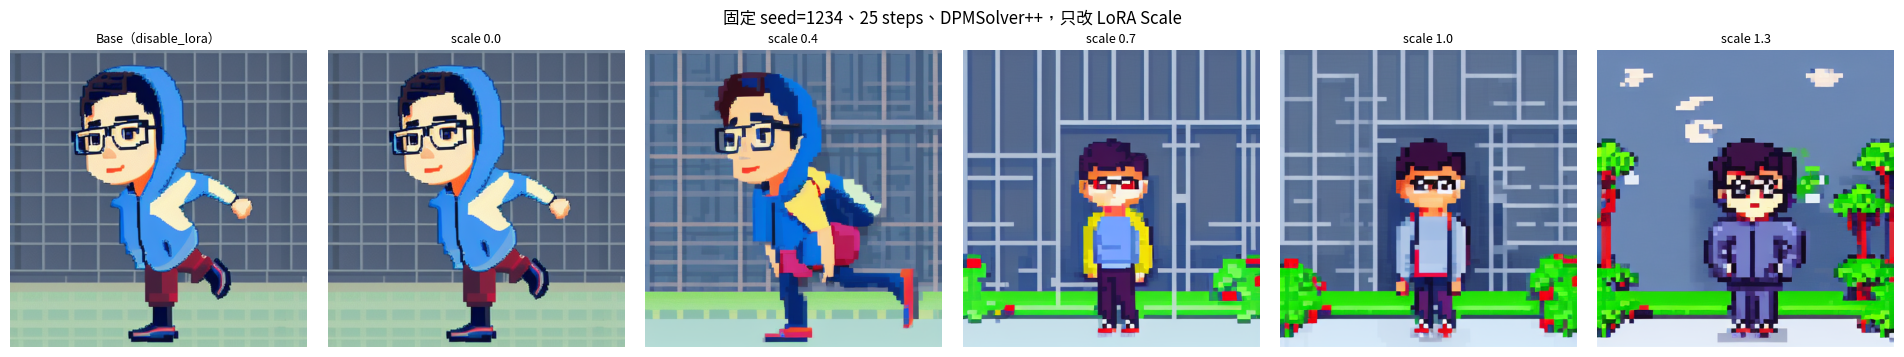

,LoRA Scale,與 Base 的平均像素差（0–255）
0,0.0,0.00
1,0.4,29.64
2,0.7,49.83
3,1.0,54.82
4,1.3,61.27


耗時 118 秒


In [ ]:
if GPU_OK:
    print("✅ GPU：", torch.cuda.get_device_name(0))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "diffusers==0.41.0", "transformers", "accelerate", "peft", "ftfy"], check=True)
    import diffusers
    print("diffusers", diffusers.__version__)
else:
    print("⏭️ 沒有偵測到 GPU，軌道 B（Lab 8–10）的程式格會自動跳過。")
    print("   要執行請到：執行階段 → 變更執行階段類型 → T4 GPU。")
# Lab 8-1：載入 LoRA 並做 Weight Sweep
PIXEL = {"repo": "artificialguybr/pixelartredmond-1-5v-pixel-art-loras-for-sd-1-5",
         "weight_name": "PixelArtRedmond15V-PixelArt-PIXARFK.safetensors",
         "adapter_name": "pixel", "trigger": "pixel art, PixArFK"}
SWEEP_SCALES = [0.0, 0.4, 0.7, 1.0, 1.3]
SWEEP_SEED = 1234
SWEEP_PROMPT = f"a young male student with short black hair and round glasses, navy hoodie, standing, {PIXEL['trigger']}"


def ensure_pixel_lora():
    pipe = get_pipe()
    if PIXEL["adapter_name"] not in loaded_adapters(pipe):
        pipe.load_lora_weights(PIXEL["repo"], weight_name=PIXEL["weight_name"], adapter_name=PIXEL["adapter_name"])
    return pipe


if GPU_OK:
    t0 = time.perf_counter()
    pipe = ensure_pixel_lora()
    use_adapter(pipe, None)
    base_img = generate(SWEEP_PROMPT, SWEEP_SEED)
    sweep_imgs = []
    for s in SWEEP_SCALES:
        use_adapter(pipe, PIXEL["adapter_name"], s)
        sweep_imgs.append(generate(SWEEP_PROMPT, SWEEP_SEED))
    for s, im in zip(SWEEP_SCALES, sweep_imgs):
        im.save(f"{OUT_DIR}/lab8_scale_{s:.1f}.png")
    show_grid([base_img] + sweep_imgs, ["Base（disable_lora）"] + [f"scale {s}" for s in SWEEP_SCALES], ncols=6,
              suptitle=f"固定 seed={SWEEP_SEED}、25 steps、DPMSolver++，只改 LoRA Scale")
    b = np.asarray(base_img, dtype=np.float32)
    diffs = [float(np.abs(np.asarray(im, dtype=np.float32) - b).mean()) for im in sweep_imgs]
    display(pd.DataFrame({"LoRA Scale": SWEEP_SCALES, "與 Base 的平均像素差（0–255）": np.round(diffs, 2)}))
    print(f"耗時 {time.perf_counter() - t0:.0f} 秒")
else:
    print("⏭️ 沒有 GPU，跳過 Lab 8-1。")

### Validation Prompts：不要只測 Training Prompt（講義 8.21）
接著固定 Scale=1.0，對五個「刻意換掉 Pose／Scene／Lighting／Clothing／Camera」的 Prompt，各產生 Base 與 LoRA 兩張圖。最後一條故意**不寫 trigger word**。

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


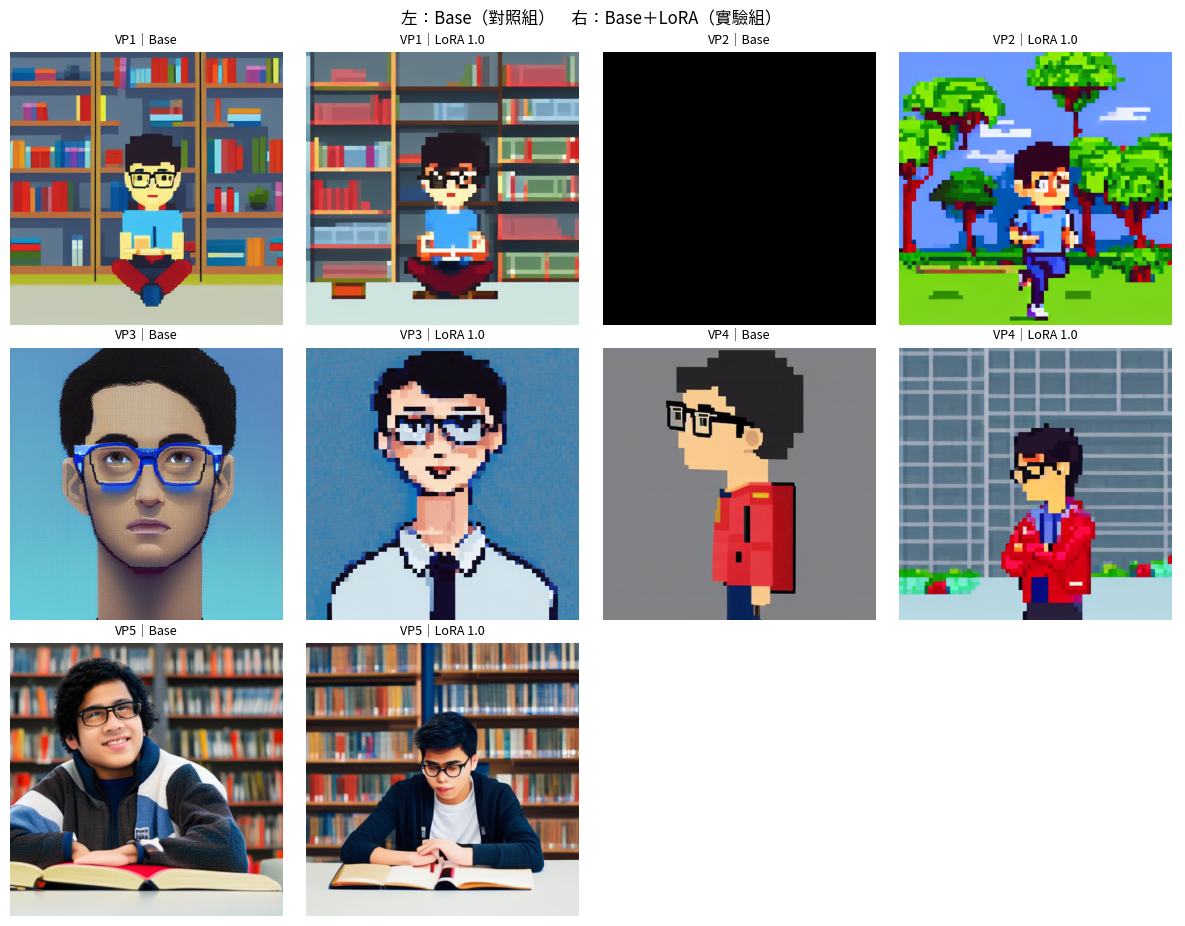

VP1: a young male student with short black hair and round glasses, sitting in a library, pixel art, PixArFK
VP2: a young male student with short black hair and round glasses, running outdoors, pixel art, PixArFK
VP3: a young male student with short black hair and round glasses, under blue lighting, close-up portrait, pixel art, PixArFK
VP4: a young male student with short black hair and round glasses, wearing a red jacket, side view, pixel art, PixArFK
VP5: a young male student with short black hair and round glasses, sitting in a library


In [ ]:
# Lab 8-2：Base vs LoRA，五個 Validation Prompts
SUBJECT = "a young male student with short black hair and round glasses"
VALIDATION = [
    f"{SUBJECT}, sitting in a library, {PIXEL['trigger']}",
    f"{SUBJECT}, running outdoors, {PIXEL['trigger']}",
    f"{SUBJECT}, under blue lighting, close-up portrait, {PIXEL['trigger']}",
    f"{SUBJECT}, wearing a red jacket, side view, {PIXEL['trigger']}",
    f"{SUBJECT}, sitting in a library",                       # 沒有 trigger word
]
LORA_SCALE = 1.0      # 🔧 TODO：改成 Lab 8-1 中你認為最平衡的 scale

if GPU_OK:
    pipe = ensure_pixel_lora()
    imgs, titles = [], []
    for i, p in enumerate(VALIDATION, 1):
        for name, cond in [("Base", None), (f"LoRA {LORA_SCALE}", PIXEL["adapter_name"])]:
            use_adapter(pipe, cond, LORA_SCALE)
            imgs.append(generate(p, SWEEP_SEED)); titles.append(f"VP{i}｜{name}")
    show_grid(imgs, titles, ncols=4, size=3.0, suptitle="左：Base（對照組）　右：Base＋LoRA（實驗組）")
    for i, p in enumerate(VALIDATION, 1):
        print(f"VP{i}: {p}")
else:
    print("⏭️ 沒有 GPU，跳過 Lab 8-2。")

In [ ]:
# Lab 8-3：講義 8.19 的比較表（請自己填）
sweep_table = pd.DataFrame({"LoRA Scale": SWEEP_SCALES, "Subject Similarity": "", "Prompt Flexibility": "",
                            "Artifact": "", "Observation": ""})
sweep_table

,LoRA Scale,Subject Similarity,Prompt Flexibility,Artifact,Observation
0,0.0,,,,
1,0.4,,,,
2,0.7,,,,
3,1.0,,,,
4,1.3,,,,


### 👀 觀察
- Scale 0.0 與 Base 的像素差：
- 開始出現 Artifact 的 Scale：
- 沒有 trigger word 的 VP5，LoRA 有沒有改變畫面：
- LoRA 穩定改變了哪些特徵？哪些特徵沒有改變？

### 反思
1. 講義 8.19 提醒：不要只選「最像 Training Image 的那張」。在這個風格 LoRA 中，「最像」對應哪個 Scale？它的 Prompt Flexibility 如何？
2. 和 Lab 3 的 Scale Sweep 比較：兩者的「Scale = 0」各代表什麼？「Scale 超過 1」各發生什麼事？

## Lab 9｜六張影像故事組＋自動一致性指標（講義 8.27）

### 問題
用 Lab 6 的 Prompt Template 生成六張故事圖，和「每張各自寫 Prompt」相比，一致性有沒有比較好？可以用數字量化嗎？

### 兩種自動指標
- **CLIP 影像相似度**：用 `openai/clip-vit-base-patch32` 把每張圖轉成向量，計算兩兩 cosine similarity，取平均。它反映整體語意與風格的接近程度。
- **色彩直方圖相關係數**：比較兩張圖的 HSV 色彩分布，反映 Palette 一致性。
- 另外計算每張圖和自己 Scene 描述的 **CLIP 圖文相似度**，當作 Scene Compliance 的粗略參考。

> 這些指標**只能輔助**Lab 7 的人工 Rubric。CLIP 分不清「同一個角色」和「同樣構圖的不同人」；色彩直方圖完全不看形狀；六張全黑的圖兩項指標都會很高。

### 實驗設計
| 條件 | Prompt | Seed |
| --- | --- | --- |
| A：Prompt Template | Lab 6 的 `build_prompt(scene)` | 六張都用 1234 |
| B：各自寫 Prompt | 每張自己寫，風格詞不固定（講義 8.15 的反例） | 六張都用 1234 |
| C（選做）：Template＋LoRA | 條件 A 的 Prompt 加上像素風 LoRA | 六張都用 1234 |

### ✍️ 我的預測
1. 條件 A 和 B，哪個 CLIP 影像相似度比較高？差多少？
2. 條件 A 的 Scene Compliance 會因為規格固定而下降嗎？

> 我的預測：
> 1.
> 2.

In [ ]:
# Lab 9-1：故事組設定（沒有執行 Lab 6 也能跑）
if "SCENES" not in globals() or "build_prompt" not in globals():
    CHARACTER = "young male student, short black hair, round glasses, navy hoodie, white sneakers"
    STYLE = ("flat editorial illustration, clean geometric shapes, navy and coral color palette, soft daylight, "
             "minimal university environment, 16:9 composition, no text")
    SCENES = [
        {"id": "01", "title": "走進校園", "action": "walking through the campus gate", "background": "tree-lined campus path", "camera": "medium shot"},
        {"id": "02", "title": "坐在教室", "action": "sitting at a desk, listening", "background": "lecture classroom", "camera": "medium shot"},
        {"id": "03", "title": "操作電腦", "action": "typing on a laptop", "background": "computer classroom", "camera": "medium close-up"},
        {"id": "04", "title": "進入實驗室", "action": "opening the lab door", "background": "multimedia lab with monitors", "camera": "medium shot"},
        {"id": "05", "title": "與同學討論", "action": "discussing ideas with a classmate", "background": "study corner with whiteboard", "camera": "medium shot"},
        {"id": "06", "title": "站上舞台", "action": "presenting a project on stage", "background": "small auditorium stage", "camera": "wide shot"},
    ]

    def scene_text(s):
        return f"{s['action']}, {s['background']}, {s['camera']}"

    def build_prompt(scene):
        return f"{CHARACTER}, {scene_text(scene)}, {STYLE}"

# 條件 B：每張各自寫的 Prompt（故意讓風格、外觀描述飄移）
ADHOC = [
    "a student walking into a campus, watercolor painting",
    "photo of a guy with long hair in a classroom",
    "3d render of a young man coding on a computer",
    "anime boy entering a science lab, red jacket",
    "two students talking, oil painting",
    "a performer on a stage, comic book style",
]
STORY_SEED, STORY_W, STORY_H = 1234, 768, 432     # 16:9（寬高需為 8 的倍數）
USE_LORA_IN_STORY = False                          # 🔧 TODO：改成 True 加跑條件 C

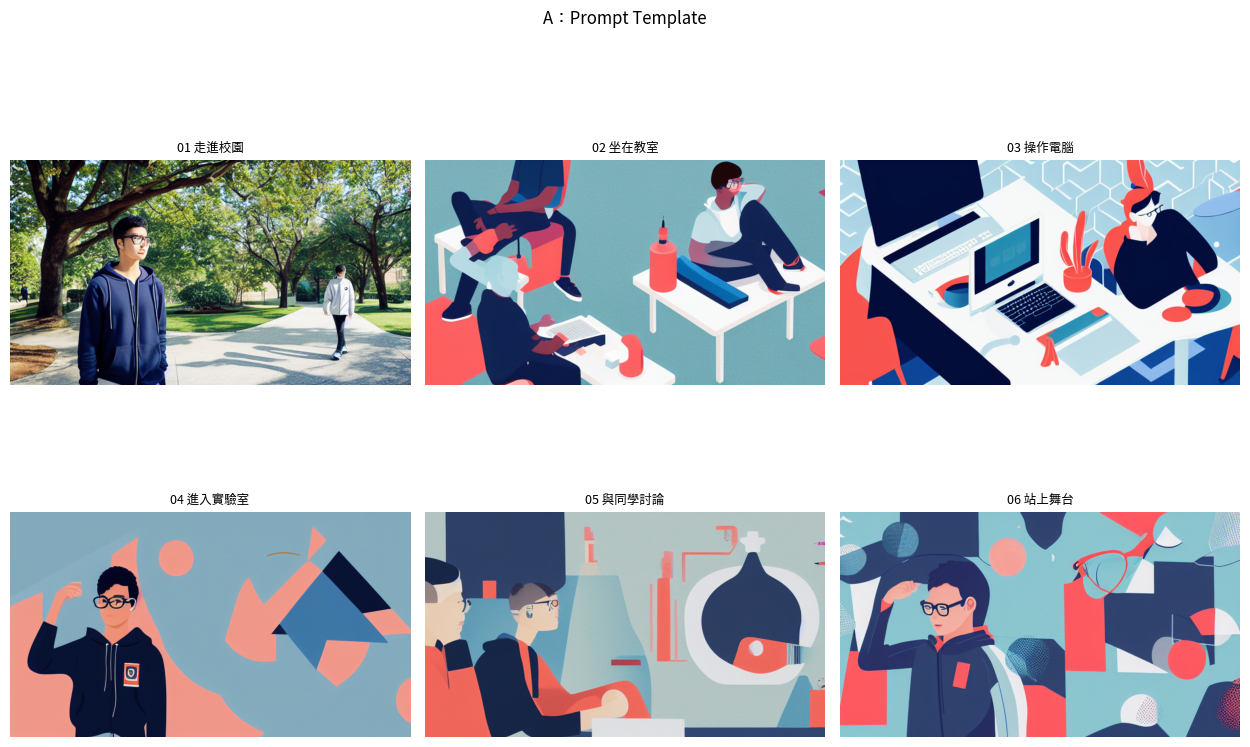

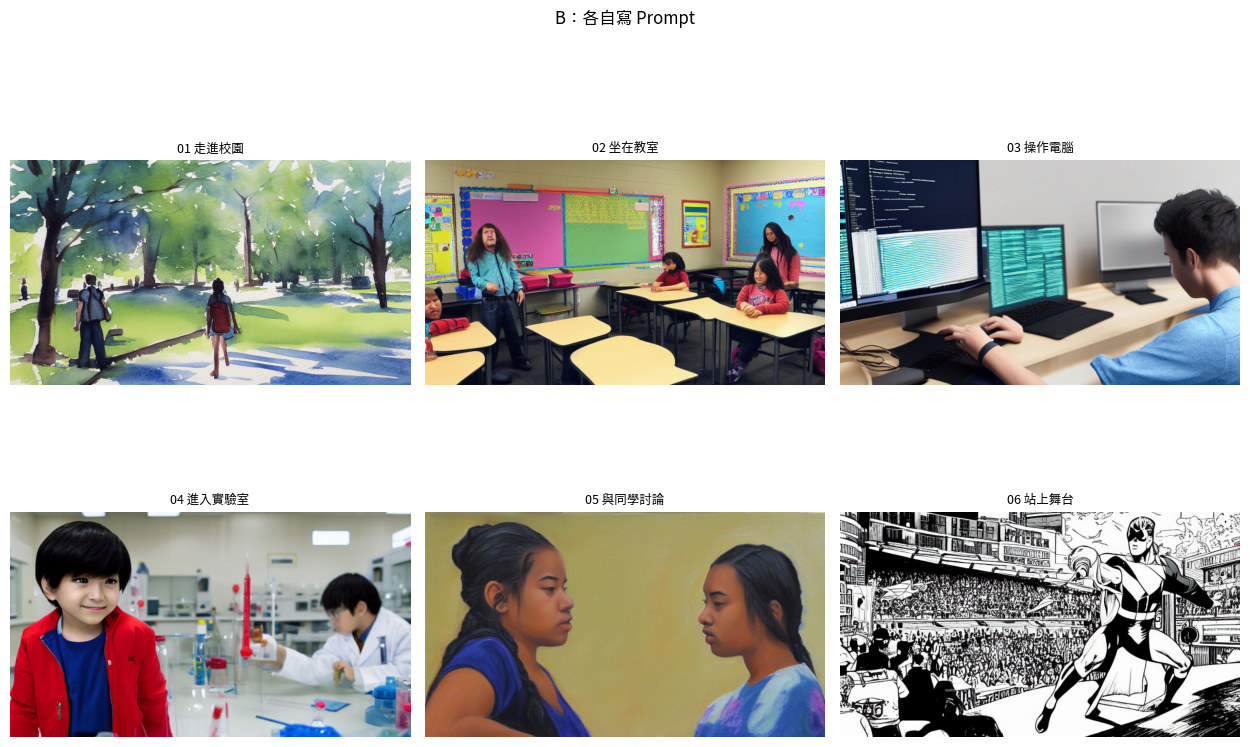

耗時 70 秒


In [ ]:
# Lab 9-2：生成故事組
def make_story(prompts, adapter=None, scale=0.7):
    pipe = get_pipe()
    if adapter:
        ensure_pixel_lora()
    if loaded_adapters(pipe):
        use_adapter(pipe, adapter, scale)
    return [generate(p, STORY_SEED, width=STORY_W, height=STORY_H) for p in prompts]


if GPU_OK:
    t0 = time.perf_counter()
    stories = {"A：Prompt Template": make_story([build_prompt(s) for s in SCENES]),
               "B：各自寫 Prompt": make_story(ADHOC)}
    if USE_LORA_IN_STORY:
        stories["C：Template＋LoRA 0.7"] = make_story([f"{build_prompt(s)}, pixel art, PixArFK" for s in SCENES],
                                                       adapter="pixel", scale=0.7)
    for cond, imgs in stories.items():
        show_grid(imgs, [f"{s['id']} {s['title']}" for s in SCENES], ncols=3, size=4.2, suptitle=cond)
        for s, im in zip(SCENES, imgs):
            im.save(f"{OUT_DIR}/lab9_{cond[0]}_{s['id']}.png")
    print(f"耗時 {time.perf_counter() - t0:.0f} 秒")
else:
    print("⏭️ 沒有 GPU，跳過 Lab 9-2。")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,條件,CLIP 影像相似度（平均）,色彩直方圖相關（平均）,Scene 圖文相似度（平均）
0,A：Prompt Template,0.761,0.127,0.212
1,B：各自寫 Prompt,0.494,0.090,0.219


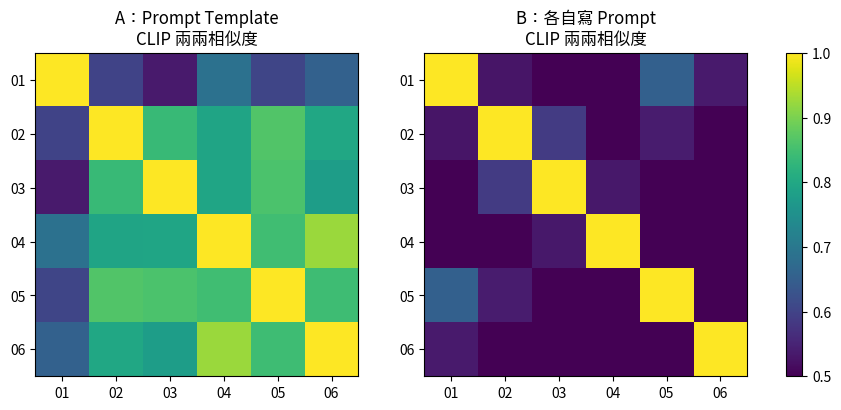

In [ ]:
# Lab 9-3：自動一致性指標
def hsv_hist(img, bins=8):
    hsv = np.asarray(img.convert("HSV")).reshape(-1, 3)
    h, _ = np.histogramdd(hsv, bins=(bins, bins, bins), range=((0, 256),) * 3)
    return h.ravel() / h.sum()


def mean_offdiag(M):
    n = M.shape[0]
    return float((M.sum() - np.trace(M)) / (n * n - n))


def story_metrics(images, scene_texts, clip_model, clip_proc):
    with torch.no_grad():
        inputs = clip_proc(text=scene_texts, images=images, return_tensors="pt", padding=True, truncation=True).to("cuda")
        out = clip_model(**inputs)
    img_emb = out.image_embeds / out.image_embeds.norm(dim=-1, keepdim=True)
    txt_emb = out.text_embeds / out.text_embeds.norm(dim=-1, keepdim=True)
    clip_sim = (img_emb @ img_emb.T).cpu().numpy()
    scene_score = (img_emb * txt_emb).sum(-1).cpu().numpy()     # 每張圖 vs 自己的 Scene 描述
    hists = np.stack([hsv_hist(im) for im in images])
    color_corr = np.corrcoef(hists)
    return clip_sim, color_corr, scene_score


if GPU_OK and "stories" in globals():
    from transformers import CLIPModel, CLIPProcessor
    clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda").eval()
    clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    texts = [scene_text(s) for s in SCENES]
    rows, mats = [], {}
    for cond, imgs in stories.items():
        cs, cc, sc = story_metrics(imgs, texts, clip_model, clip_proc)
        mats[cond] = cs
        rows.append({"條件": cond, "CLIP 影像相似度（平均）": round(mean_offdiag(cs), 3),
                     "色彩直方圖相關（平均）": round(mean_offdiag(cc), 3), "Scene 圖文相似度（平均）": round(float(sc.mean()), 3)})
    display(pd.DataFrame(rows))
    fig, axes = plt.subplots(1, len(mats), figsize=(5 * len(mats), 4.2))
    for ax, (cond, M) in zip(np.atleast_1d(axes), mats.items()):
        im = ax.imshow(M, vmin=0.5, vmax=1.0, cmap="viridis")
        ax.set_xticks(range(6), [s["id"] for s in SCENES]); ax.set_yticks(range(6), [s["id"] for s in SCENES])
        ax.set_title(f"{cond}\nCLIP 兩兩相似度")
    fig.colorbar(im, ax=axes, fraction=0.03); plt.show()
else:
    print("⏭️ 沒有 GPU 或尚未生成故事組，跳過 Lab 9-3。")

### 👀 觀察
| 條件 | CLIP 影像相似度 | 色彩相關 | Scene 圖文相似度 | 我的 Rubric 平均（Lab 7） |
| --- | --- | --- | --- | --- |
| A |  |  |  |  |
| B |  |  |  |  |
| C（選做） |  |  |  |  |

- 最一致的一張與最不一致的一張（講義基礎練習 3）：

### 反思
1. 自動指標和你的人工評分一致嗎？舉一個兩者不一致的例子，說明是哪個指標「看錯」了。
2. 六張都用同一個 seed，對 CLIP 相似度可能有什麼影響？把 `STORY_SEED` 改成每張不同（例如 `1234 + i`）要怎麼改程式？你預期結果如何？
3. 照講義 8.27 Step 6：挑最低分的兩張，記錄「問題 → 修改哪個 Condition → 為什麼 → 結果有沒有改善」。

## Lab 10｜（選做，約 20–30 分鐘）自己訓練一個 DreamBooth-LoRA（講義 8.8、8.23 Route C）

### 問題
DreamBooth 決定「怎麼讓模型學特定 Subject」，LoRA 決定「用什麼節省參數的方式完成適配」（講義 8.8）。只用 5 張照片，在免費 T4 上能學到什麼？會不會過擬合？

### 使用的資源
| 項目 | 內容 |
| --- | --- |
| 訓練腳本 | diffusers 官方 `examples/dreambooth/train_dreambooth_lora.py`，版本釘在已安裝的 diffusers 版本（v0.41.0） |
| 資料 | Hugging Face 資料集 `diffusers/dog-example`，5 張同一隻狗的照片（檔名標示來自 Unsplash） |
| Instance Prompt | `a photo of sks dog`（`sks` 是識別詞） |
| 設定 | 512×512、batch 1、lr 1e-4、300 steps、rank 4、fp16 mixed precision、gradient checkpointing、只訓練 UNet 的 LoRA，不做 Prior Preservation |

### 先講清楚的現實限制
- 免費 Colab 可能在訓練中斷線或分配不到 T4；中斷就重跑，腳本會從頭開始。
- 300 steps 在 T4 上大約 5～10 分鐘，加上下載模型，整個 Lab 抓 20～30 分鐘。
- 5 張照片、沒有 Prior Preservation，**很可能過擬合**：背景、角度會很像訓練照片。這正是要觀察的現象，不是失敗。
- 這一格會先釋放 Lab 8／9 的 pipeline，避免 GPU 記憶體不足。

### ✍️ 我的預測
1. 訓練後，`a photo of sks dog sitting in a library` 能把狗放進圖書館嗎？
2. `a photo of a dog`（沒有 sks）會不會也變成訓練照片中的那隻狗？

> 我的預測：
> 1.
> 2.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

訓練腳本版本： v0.41.0


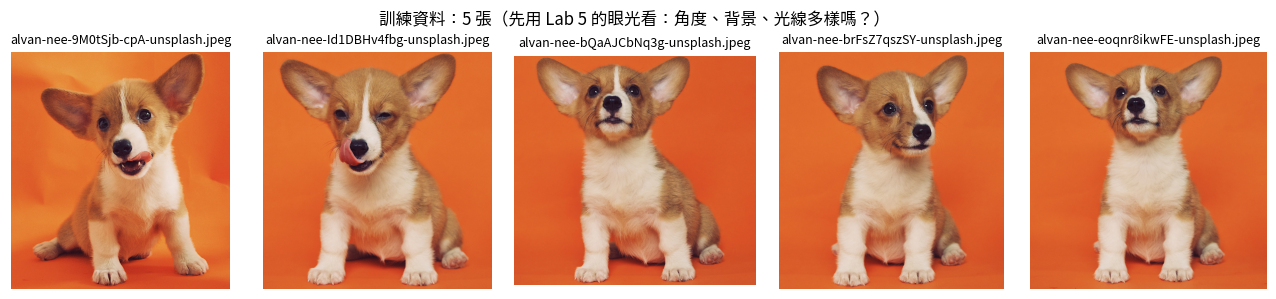

In [ ]:
# Lab 10-1：下載資料與訓練腳本（版本對齊）
DOG_DIR, LORA_OUT = "dog_example", "w08_dog_lora"
TRAIN_STEPS, LORA_RANK = 300, 4       # 🔧 可調，但每次只改一個

if GPU_OK:
    import urllib.request, diffusers
    from huggingface_hub import snapshot_download
    from PIL import Image
    snapshot_download("diffusers/dog-example", repo_type="dataset", local_dir=DOG_DIR, allow_patterns=["*.jpeg"])
    ver = diffusers.__version__
    tag = f"v{ver}" if "dev" not in ver else "main"
    script_url = f"https://raw.githubusercontent.com/huggingface/diffusers/{tag}/examples/dreambooth/train_dreambooth_lora.py"
    urllib.request.urlretrieve(script_url, "train_dreambooth_lora.py")
    print("訓練腳本版本：", tag)
    dog_files = sorted(f for f in os.listdir(DOG_DIR) if f.endswith(".jpeg"))
    show_grid([Image.open(os.path.join(DOG_DIR, f)) for f in dog_files], dog_files, ncols=5, size=2.6,
              suptitle=f"訓練資料：{len(dog_files)} 張（先用 Lab 5 的眼光看：角度、背景、光線多樣嗎？）")
else:
    print("⏭️ 沒有 GPU，跳過 Lab 10-1。")

In [ ]:
# Lab 10-2：訓練（T4 約 5～10 分鐘）
if GPU_OK:
    release_pipe()
    cmd = [sys.executable, "train_dreambooth_lora.py",
           f"--pretrained_model_name_or_path={BASE_MODEL}",
           f"--instance_data_dir={DOG_DIR}",
           f"--output_dir={LORA_OUT}",
           "--instance_prompt=a photo of sks dog",
           "--resolution=512", "--train_batch_size=1", "--gradient_accumulation_steps=1",
           "--gradient_checkpointing", "--learning_rate=1e-4", "--lr_scheduler=constant", "--lr_warmup_steps=0",
           f"--max_train_steps={TRAIN_STEPS}", f"--rank={LORA_RANK}", "--checkpointing_steps=100000",
           "--mixed_precision=fp16", "--seed=0", "--report_to=tensorboard"]
    t0 = time.perf_counter()
    env = dict(os.environ, TQDM_MININTERVAL="15")
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in proc.stdout:
        if line.strip():
            print(line.rstrip()[-200:])
    proc.wait()
    print(f"結束碼 {proc.returncode}，耗時 {(time.perf_counter() - t0) / 60:.1f} 分鐘")
    if proc.returncode == 0:
        print("輸出檔案：", os.listdir(LORA_OUT))
else:
    print("⏭️ 沒有 GPU，跳過 Lab 10-2。")

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
10/25/2026 10:19:28 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cuda
Mixed precision type: fp16
10/25/2026 10:19:28 - INFO - httpx - HTTP Request: GET https://huggingface.co/api/models/stable-diffusion-v1-5/stable-diffusion-v1-5 "HTTP/1.1 200 OK"
9 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/resolve/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/tokenizer/config.json "HTTP/1.1 404 Not Found"
INFO - httpx - HTTP Request: GET https://huggingface.co/api/models/stable-diffusion-v1-5/stable-diffusion-v1-5/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
10/25/2026 10:19:29 - INFO - httpx - HTTP Request: GET https://huggingface.co/api/models/stable-diffusion-v1-5/stable-diffusion-v1-5/tree/main?recursive

In [ ]:
# Lab 10-3：Base vs Adapter（固定 seed）
DOG_PROMPTS = [
    "a photo of sks dog in a bucket",                 # 接近訓練資料
    "a photo of sks dog sitting in a library",        # 換場景
    "a photo of sks dog wearing a blue scarf, side view",  # 換服飾與角度
    "a photo of a dog",                               # 沒有識別詞：Adapter 有沒有「洩漏」到整個類別？
]
if GPU_OK and os.path.exists(os.path.join(LORA_OUT, "pytorch_lora_weights.safetensors")):
    pipe = get_pipe()
    if "sks_dog" not in loaded_adapters(pipe):
        pipe.load_lora_weights(LORA_OUT, weight_name="pytorch_lora_weights.safetensors", adapter_name="sks_dog")
    imgs, titles = [], []
    for i, p in enumerate(DOG_PROMPTS, 1):
        for label, name, s in [("Base", None, 0), ("LoRA 0.7", "sks_dog", 0.7), ("LoRA 1.0", "sks_dog", 1.0)]:
            use_adapter(pipe, name, s)
            imgs.append(generate(p, 2026)); titles.append(f"P{i}｜{label}")
    show_grid(imgs, titles, ncols=3, size=3.2, suptitle="固定 seed=2026：Base vs 自己訓練的 DreamBooth-LoRA")
    for i, p in enumerate(DOG_PROMPTS, 1):
        print(f"P{i}: {p}")
else:
    print("⏭️ 沒有 GPU 或尚未完成訓練，跳過 Lab 10-3。")

⏭️ 沒有 GPU 或尚未完成訓練，跳過 Lab 10-3。


### 👀 觀察
- 訓練時間與最後的 loss：
- P2、P3 換場景、換服飾成功了嗎？
- P4（沒有 sks）有沒有變成訓練照片中的狗？

### 反思
1. 這次訓練沒有用 Prior Preservation。對照講義 8.8，P4 的結果說明了什麼？
2. 照講義 8.24，為這個 LoRA 寫一份 Metadata：Base Model、Rank、Training Dataset、Trigger、Recommended Scale、License、Training Tool、Training Parameters。

---
## 本週重點整理
1. **LoRA 省的是訓練成本**：凍結 $W$，只學 $\Delta W = BA$。4096×4096、r=16 時只需更新約 0.78% 的參數（Lab 1）。Lab 3 的程式裡，這件事就是 `requires_grad_(False)` 加上兩個新的 `nn.Parameter`。
2. **低秩是假設**：有結構的矩陣，能量集中在少數方向（Lab 2）。任務真正需要的調整超過 Rank 時，LoRA 會學不起來（Lab 3 動手改 1）。
3. **Rank 與 Scale 都是實驗變因**：Rank 越大不一定越好；Scale 是在 Base 與 Adapter 之間調整影響程度，1.3 不等於「品質 130%」，Scale 0 就是 Base Model 對照組（Lab 3、Lab 8）。
4. **Parameter-Efficient 不等於 Data-Efficient**：Identity 與背景在資料中完全綁在一起時，模型會學背景（Lab 4）。資料要「目標 Concept 穩定，非必要因素適度變化」，而且光是加量不加變化沒有用。
5. **按 Train 之前先寫 Dataset Card**：來源、授權、多樣性、Caption、Validation Prompts，以及 Privacy 與用途限制（Lab 5）。
6. **一致性要拆開、要量化**：Visual Specification＋Prompt Template 固定規格（Lab 6），Rubric 讓結論可以比較（Lab 7），自動指標只能輔助人工評分（Lab 9）。
7. **LoRA 是工具箱的一項工具**：先判斷缺的是文字控制、外觀參考（IP-Adapter）、結構控制（ControlNet），還是真的需要學新 Concept（講義 8.18）。

---
## 🛡️ 三道防線驗證與 AI 協作紀錄

### 1. 閱讀理解檢核（看）
* 用自己的話說明 Lab 3 `LoRALinear.forward` 中，哪一項來自凍結的 $W_0$、哪一項會被訓練？為什麼 $B$ 初始化成 0 時，訓練前的輸出和 Base Model 完全相同？
* Lab 4 的權重圖在 0% 去相關時亮在背景。這張圖告訴你模型用什麼線索判斷角色？
* Lab 5 的 `audit_dataset` 用 Cramér's V 找出哪兩個欄位高度相關？這對 LoRA 訓練的意義是什麼？

### 2. 預測執行檢核（想）
* 如果把 Lab 3 的 LoRA rank 從 2 改成 1（TRUE_RANK 仍是 2），test loss 會怎麼變？大約會接近哪一個模型的數字？執行後對照。
* 如果 Lab 1 的 rank 設成 2048（4096×4096），LoRA 參數量和 Full Fine-tuning 相比如何？
* 如果 Lab 4 去相關樣本只有 5%，交換背景測試的準確率大約落在哪裡？用 Diversity Sweep 的曲線推估後再實測。
* （軌道 B）Lab 8 中 `set_adapters(..., adapter_weights=[0.0])` 和 `disable_lora()` 產生的圖會完全相同嗎？用像素差驗證。

### 3. 邊界測試（踹）
* Lab 1：`lora_param_count(4096, 4096, 0)` 和 `lora_param_count(64, 64, 100)` 分別會發生什麼？這樣的處理合理嗎？
* Lab 3：把 LoRA Scale 設成 `-1.0`，新任務誤差和「偏離 Base 的程度」會怎樣？說明原因。
* Lab 6：Scene 裡寫 `blond ponytail`、`in the style of Ghibli`，檢查器抓得到嗎？要怎麼補強？
* Lab 9：如果 safety checker 把六張圖都變成全黑，CLIP 影像相似度與色彩相關會變成多少？這說明自動指標有什麼盲點？

### 📝 AI 協作紀錄模板
```markdown
- 使用工具：(例如 ChatGPT / Claude / Gemini)
- 我提出的 CGRF 提示：
  - Context:
  - Goal:
  - Restrictions:
  - Format:
- AI 建議的做法：
- 我採用、修改或拒絕的部分：
- 驗證方式與結果：
```

---
## 📦 繳交清單
請繳交執行完成的 `.ipynb`（保留輸出），檔名 `W08_學號_姓名.ipynb`。

**必做（軌道 A，對應講義 8.23 Route A）**
- [ ] Lab 1–7 每一個「✍️ 我的預測」與「👀 觀察」格都已填寫（預測要在執行前寫，錯了不扣分）。
- [ ] Lab 3：五個模型的比較表，以及兩個「動手改」的結果與解釋。
- [ ] Lab 4：Diversity Sweep 表格，以及「1600 張、0% 去相關」的結果。
- [ ] Lab 5：通過 `check_card` 的 Dataset Card（Markdown 輸出）。
- [ ] Lab 6：你自己的 Visual Specification、六個 Prompt，以及 `w08_story_manifest.json`。
- [ ] Lab 7：至少一份你自己的 Rubric 評分表與一句結論。
- [ ] 三道防線：每一道至少回答兩題。
- [ ] AI 協作紀錄：至少一筆。

**選做（軌道 B，對應 Route B／Route C）**
- [ ] Lab 8：Weight Sweep 圖、Validation Prompts 對照圖、填好的 8.19 比較表。
- [ ] Lab 9：A／B 兩組故事圖、指標表，以及「最一致與最不一致的一張」說明。
- [ ] Lab 10：訓練紀錄（steps、rank、時間）、Base vs Adapter 對照圖、LoRA Metadata。